<a href="https://colab.research.google.com/github/angelolucero-cloud/GO-Grupo-2/blob/main/Parte_A_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ENTREGA 1 - PARTE A
# Carga de datos desde GitHub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dirección del repositorio (corregida)
repo = "https://raw.githubusercontent.com/valentinabenitez-crypto/Cargar-COLLAB/main/Datos/"

# Cargar archivos
llenado = pd.read_csv(repo + "calidad_llenado.csv")
atributos = pd.read_csv(repo + "calidad_atributos.csv")
especificaciones = pd.read_csv(repo + "especificaciones_calidad.csv")
maestro = pd.read_csv(repo + "maestro_sku.csv")
demanda = pd.read_csv(repo + "demanda_semanal.csv")

# Verificar la carga
print("Archivos cargados correctamente")

print("Calidad llenado:", llenado.shape)
print("Calidad atributos:", atributos.shape)
print("Especificaciones:", especificaciones.shape)
print("Maestro SKU:", maestro.shape)
print("Demanda semanal:", demanda.shape)

display(llenado.head())

Archivos cargados correctamente
Calidad llenado: (4200, 10)
Calidad atributos: (210, 8)
Especificaciones: (3, 6)
Maestro SKU: (9, 13)
Demanda semanal: (1404, 10)


,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


Exploración y diagnóstico de los datos: comprobar que las mediciones de llenado estén correctamente registradas antes de construir las cartas de control.


In [2]:
# BLOQUE 2: EXPLORACIÓN Y DIAGNÓSTICO DE DATOS

# Revisar las primeras 5 filas
print(llenado.head())

# Revisar cantidad de filas y columnas
print("Dimensiones:")
print(llenado.shape)

# Revisar nombres y tipos de columnas
print("Información general:")
llenado.info()

# Obtener estadísticas descriptivas
print("Estadísticas descriptivas:")
print(llenado.describe())

   subgrupo       fecha  semana_registro      turno linea      sku  formato_L  \
0         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
1         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
2         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
3         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
4         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   

    hora  n_obs  volumen_mL  
0  06:00      1      500.86  
1  06:00      2      502.11  
2  06:00      3      503.12  
3  06:00      4      502.60  
4  06:00      5      499.11  
Dimensiones:
(4200, 10)
Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subgrupo         4200 non-null   int64  
 1   fecha            4200 non-null   objec

 Validación de datos
Antes de realizar el análisis estadístico del proceso de llenado, se realiza una validación inicial de la base de datos con el objetivo de identificar posibles problemas que puedan afectar los resultados. Para esto, se revisa la existencia de valores faltantes, registros duplicados, consistencia en el tamaño de los subgrupos de medición y distribución de las observaciones según línea de producción, formato y turno.
Esta etapa permite asegurar que los datos utilizados posteriormente para la construcción de cartas de control representen adecuadamente el comportamiento del proceso productivo.

In [3]:
#BLOQUE 3 validación de datos
#1
# Revisar valores faltantes

print("Valores faltantes por columna:")
print(llenado.isnull().sum())

#2
#Revisar registros duplicados

print("Cantidad de filas duplicadas:")
print(llenado.duplicated().sum())

#3
# Revisar tamaño de los subgrupos

cantidad_subgrupo = llenado.groupby("subgrupo").size()

print("Cantidad de mediciones por subgrupo:")
print(cantidad_subgrupo.value_counts())

#4
# Identificar subgrupos que no tienen 5 observaciones

subgrupos_incorrectos = cantidad_subgrupo[cantidad_subgrupo != 5]

print("Subgrupos con cantidad distinta de 5:")
print(subgrupos_incorrectos)

# 5
#Revisar cantidad de mediciones por línea

print("Mediciones por línea:")
print(llenado["linea"].value_counts())


#6
# Revisar cantidad por formato

print("\nMediciones por formato:")
print(llenado["formato_L"].value_counts())


#7
# Revisar cantidad por turno

print("\nMediciones por turno:")
print(llenado["turno"].value_counts())

Valores faltantes por columna:
subgrupo           0
fecha              0
semana_registro    0
turno              0
linea              0
sku                0
formato_L          0
hora               0
n_obs              0
volumen_mL         0
dtype: int64
Cantidad de filas duplicadas:
0
Cantidad de mediciones por subgrupo:
5    840
Name: count, dtype: int64
Subgrupos con cantidad distinta de 5:
Series([], dtype: int64)
Mediciones por línea:
linea
L2    3000
L1    1200
Name: count, dtype: int64

Mediciones por formato:
formato_L
3.0    1560
1.5    1440
0.5    1200
Name: count, dtype: int64

Mediciones por turno:
turno
A (06-14)    1600
B (14-22)    1600
C (22-06)    1000
Name: count, dtype: int64


1. "La base de datos de llenado no presenta valores faltantes, por lo que todas las observaciones pueden ser consideradas en el análisis estadístico posterior."
2. "No se identificaron registros duplicados, evitando que algunas mediciones tengan una influencia artificialmente mayor dentro del análisis."
3. Todos los subgrupos contienen cinco observaciones, cumpliendo la estructura necesaria para aplicar cartas de control X̄–R.
4. No se encontraron subgrupos con tamaños incorrectos, por lo que no fue necesario realizar ajustes en la estructura de los datos.
5. La línea L2 concentra la mayor cantidad de mediciones (3000), mientras que L1 posee 1200 observaciones. El análisis posterior considerará cada línea por separado.
6. Se identificaron tres formatos de producción (0,5 L, 1,5 L y 3,0 L). Debido a sus diferentes volúmenes nominales, serán analizados de manera independiente.
7. Se cuenta con registros de los tres turnos de operación, permitiendo evaluar posteriormente si existen diferencias asociadas al turno de producción.

**Selección de la carta de control**.

Las mediciones de volumen corresponden a una variable continua y se encuentran organizadas en subgrupos racionales de tamaño constante \(n=5\). Debido a que se trabaja con subgrupos pequeños, se seleccionaron cartas \(X̄-R\): la carta \(X̄\) permite monitorear cambios en el nivel medio de llenado, mientras que la carta \(R\) permite evaluar la variabilidad dentro de cada subgrupo mediante su rango. La alternativa \(X̄-S\) resulta más apropiada para subgrupos de mayor tamaño, donde la desviación estándar aprovecha mejor la información contenida en las observaciones.

**PREPARACIÓN DE DATOS CARTAS X-R**

Para construir las cartas de control X̄–R, se agrupan las mediciones individuales en subgrupos racionales de cinco observaciones. Para cada subgrupo se calcula el promedio del volumen y el rango, permitiendo evaluar tanto el nivel central del proceso como su variabilidad.

In [4]:
#BLOQUE 4 Preparación de datos para cartas X-R
# Crear tabla con promedio y rango por subgrupo

datos_control = llenado.groupby("subgrupo").agg(media_volumen=("volumen_mL", "mean"),
    rango_volumen=("volumen_mL", lambda x: x.max() - x.min()),
    linea=("linea", "first"),
    formato_L=("formato_L", "first"),
    turno=("turno", "first")
).reset_index()


# Mostrar primeros resultados

datos_control.head()


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno
0,1,501.560,4.01,L1,0.5,A (06-14)
1,2,501.752,5.17,L1,0.5,A (06-14)
2,3,503.630,4.13,L1,0.5,A (06-14)
3,4,503.172,2.10,L1,0.5,A (06-14)
4,5,503.396,8.49,L1,0.5,B (14-22)


Se transformaron las mediciones individuales en subgrupos racionales de cinco observaciones, calculando para cada uno la media y el rango del volumen de llenado. Esta estructura permitirá construir las cartas X̄–R, evaluando tanto el nivel promedio del proceso como su variabilidad.

 Separación de procesos por línea y formato
Y escribe:
Debido a que el proceso de llenado presenta diferentes líneas de producción y formatos de producto, los análisis estadísticos se realizarán de manera independiente para cada combinación línea-formato. Esto permite comparar procesos equivalentes y evitar distorsiones producto de diferencias en los volúmenes nominales.

In [5]:
#BLOQUE 5 Separación de procesos para análisis estadístico
# Revisar combinaciones de línea y formato

datos_control[["linea", "formato_L"]].drop_duplicates()

# Separar procesos por línea y formato

proceso_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5)
]

proceso_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5)
]

proceso_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0)
]


print("L1 - 0.5 L:", proceso_L1_05.shape)
print("L2 - 1.5 L:", proceso_L2_15.shape)
print("L2 - 3.0 L:", proceso_L2_30.shape)

L1 - 0.5 L: (240, 6)
L2 - 1.5 L: (288, 6)
L2 - 3.0 L: (312, 6)


Se identificaron tres combinaciones de línea y formato, las cuales fueron separadas para realizar el análisis estadístico de manera independiente y evitar mezclar procesos con distintos volúmenes nominales.
¿Qué significa el resultado (240, 6)?
- 240: cantidad de subgrupos correspondientes a la línea L1 y formato 0,5 L.
- 6: cantidad de columnas de nuestra tabla datos_control.

In [6]:
#BLOQUE 6 : COMPROBACIONES
# Agregar la semana de cada subgrupo a datos_control

semana_subgrupo = llenado[
    ["subgrupo", "semana_registro"]
].drop_duplicates()

datos_control = pd.merge(
    datos_control,
    semana_subgrupo,
    on="subgrupo",
    how="left"
)

display(datos_control.head())

,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro
0,1,501.560,4.01,L1,0.5,A (06-14),1
1,2,501.752,5.17,L1,0.5,A (06-14),1
2,3,503.630,4.13,L1,0.5,A (06-14),1
3,4,503.172,2.10,L1,0.5,A (06-14),1
4,5,503.396,8.49,L1,0.5,B (14-22),1


In [7]:
# Cantidad de subgrupos por semana y proceso

print(
    datos_control.groupby(
        ["linea", "formato_L", "semana_registro"]
    ).size()
)

linea  formato_L  semana_registro
L1     0.5        1                  24
                  2                  24
                  3                  24
                  4                  24
                  5                  24
                  6                  24
                  7                  24
                  8                  24
                  9                  24
                  10                 24
L2     1.5        1                  20
                  2                  32
                  3                  28
                  4                  40
                  5                  16
                  6                  24
                  7                  32
                  8                  24
                  9                  36
                  10                 36
       3.0        1                  40
                  2                  28
                  3                  32
                  4                  20
      

**Definición de Fase I y Fase II**

Se utilizaron las semanas 1 y 2 como período candidato de Fase I, ya que corresponden al tramo cronológicamente inicial de la base y proporcionan una cantidad suficiente de subgrupos para estimar límites preliminares de control. Este período contiene 48 subgrupos para L1–0,5 L, 52 para L2–1,5 L y 68 para L2–3,0 L. Las semanas 3 a 10 se reservaron como Fase II, de modo que pudieran ser evaluadas posteriormente utilizando los límites obtenidos exclusivamente a partir del período inicial. La separación evita recalcular los límites con las mismas observaciones que posteriormente serán utilizadas para monitorear el proceso.

In [8]:
# BLOQUE 7: DEFINICIÓN DE FASE I Y FASE II

datos_control["fase"] = "II"

datos_control.loc[
    datos_control["semana_registro"].isin([1, 2]),
    "fase"
] = "I"

print(datos_control["fase"].value_counts())

display(datos_control.head())

fase
II    672
I     168
Name: count, dtype: int64


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
0,1,501.560,4.01,L1,0.5,A (06-14),1,I
1,2,501.752,5.17,L1,0.5,A (06-14),1,I
2,3,503.630,4.13,L1,0.5,A (06-14),1,I
3,4,503.172,2.10,L1,0.5,A (06-14),1,I
4,5,503.396,8.49,L1,0.5,B (14-22),1,I


En consecuencia, los límites obtenidos no deben interpretarse como límites definitivos de un proceso estable, sino como una línea base preliminar utilizada para identificar posibles cambios durante la Fase II.

In [9]:
# FASE I DEL PROCESO L1 - 0.5 L

fase1_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["fase"] == "I")
]

print("Cantidad de subgrupos en Fase I:")
print(fase1_L1_05.shape[0])

Cantidad de subgrupos en Fase I:
48


In [10]:
# Promedio de las medias de los subgrupos
media_medias = fase1_L1_05["media_volumen"].mean()

# Promedio de los rangos de los subgrupos
media_rangos = fase1_L1_05["rango_volumen"].mean()

print("Media de medias:", media_medias)
print("Media de rangos:", media_rangos)

Media de medias: 502.643625
Media de rangos: 4.749583333333333


Obtenemos desde las tablas impartidas en clases de calidad 2 las constantes # Constantes para cartas X barra - R con subgrupos de tamaño n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

In [11]:
# Constantes para n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

# Límites de la carta R
LC_R = media_rangos
LSC_R = D4 * media_rangos
LIC_R = D3 * media_rangos

# Límites de la carta X barra
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

print("Carta R")
print("LIC:", LIC_R)
print("LC:", LC_R)
print("LSC:", LSC_R)

print("\nCarta X barra")
print("LIC:", LIC_X)
print("LC:", LC_X)
print("LSC:", LSC_X)

Carta R
LIC: 0.0
LC: 4.749583333333333
LSC: 10.040619166666666

Carta X barra
LIC: 499.90311541666665
LC: 502.643625
LSC: 505.3841345833333


In [12]:
# Revisar puntos fuera de los límites en la carta R - Fase I

fuera_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Subgrupos fuera de control en la carta R:")
display(fuera_R)

Subgrupos fuera de control en la carta R:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
91,92,502.946,10.06,L1,0.5,B (14-22),2,I


In [13]:
# Revisar las mediciones originales del subgrupo 92

subgrupo_92 = llenado[
    llenado["subgrupo"] == 92
]

display(subgrupo_92)

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
455,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,1,503.56
456,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,2,503.12
457,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,3,506.54
458,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,4,505.03
459,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,5,496.48


Ahora tenemos que seguir investigando porque hay ese valor en este subgrupo por lo que iniciaremos una búsqueda de que salio mal, primero veremos los subgrupos cercanos para tener mas info

In [14]:
# Revisar subgrupos cercanos al 92

vecinos_92 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["subgrupo"] >= 88) &
    (datos_control["subgrupo"] <= 96)
]

display(
    vecinos_92[
        ["subgrupo", "media_volumen", "rango_volumen",
         "turno", "semana_registro"]
    ]
)

,subgrupo,media_volumen,rango_volumen,turno,semana_registro
87,88,503.312,1.87,A (06-14),2
88,89,502.768,6.72,B (14-22),2
89,90,502.888,6.26,B (14-22),2
90,91,503.330,5.80,B (14-22),2
91,92,502.946,10.06,B (14-22),2
92,93,501.440,5.88,A (06-14),2
93,94,503.434,5.98,A (06-14),2
94,95,501.722,4.17,A (06-14),2
95,96,502.652,4.58,A (06-14),2


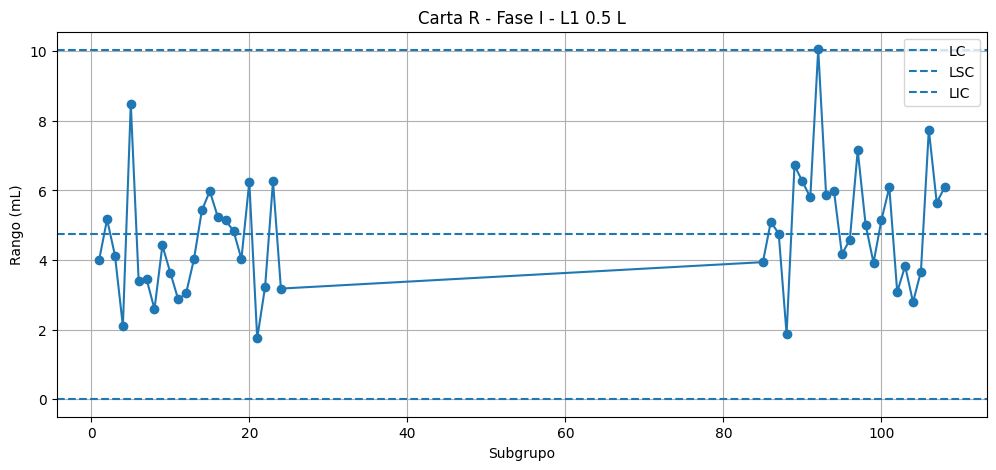

In [15]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["subgrupo"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [16]:
# Crear orden consecutivo para los subgrupos de Fase I
fase1_L1_05 = fase1_L1_05.copy()

fase1_L1_05["orden"] = range(1, len(fase1_L1_05) + 1)

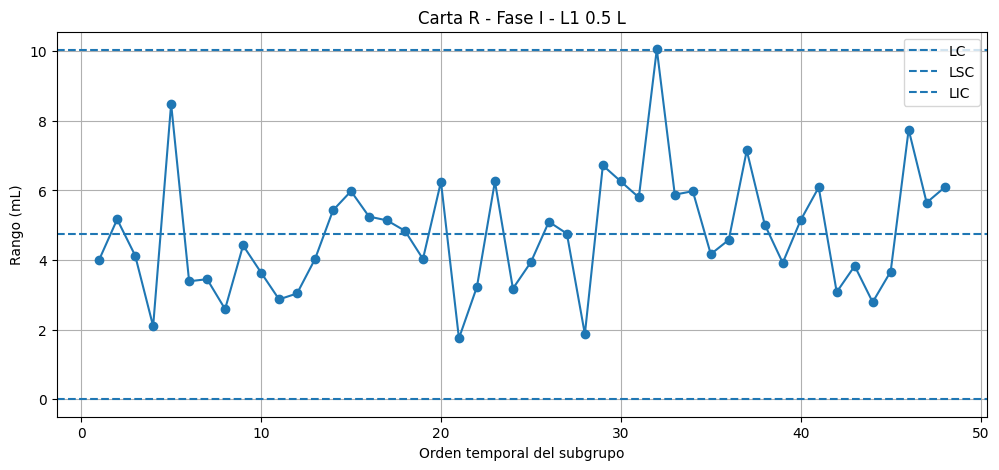

In [17]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["orden"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Orden temporal del subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [18]:
# Regla 1: punto fuera de los límites de control

regla1_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Regla 1 - Puntos fuera de los límites:")
display(regla1_R)

Regla 1 - Puntos fuera de los límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
91,92,502.946,10.06,L1,0.5,B (14-22),2,I,32


Se optó por aplicar un conjunto acotado de reglas de Nelson, evitando mezclar criterios de distintos sistemas y reduciendo el riesgo de falsas alarmas. Se consideraron tres patrones principales: puntos fuera de los límites de control, rachas prolongadas al mismo lado de la línea central y tendencias sostenidas crecientes o decrecientes. Esta selección permite detectar tanto señales extremas como comportamientos no aleatorios del proceso, manteniendo el análisis consistente con lo revisado en clases. 2_Calidad_II

In [19]:
# Regla 2 de Nelson:
# 9 puntos consecutivos al mismo lado de la línea central

valores_R = fase1_L1_05["rango_volumen"].tolist()
subgrupos_R = fase1_L1_05["subgrupo"].tolist()

senales_regla2 = []

for i in range(len(valores_R) - 8):

    grupo = valores_R[i:i+9]

    todos_arriba = all(valor > LC_R for valor in grupo)
    todos_abajo = all(valor < LC_R for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_regla2.append(subgrupos_R[i:i+9])

print("Regla 2 - 9 puntos consecutivos al mismo lado de LC:")
print(senales_regla2)

Regla 2 - 9 puntos consecutivos al mismo lado de LC:
[]


In [20]:
# Tendencia de 6 puntos consecutivos en la carta R

senales_tendencia_R = []

for i in range(len(valores_R) - 5):

    grupo = valores_R[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_R.append(
            subgrupos_R[i:i+6]
        )

print("Tendencias sostenidas detectadas en R:")
print(senales_tendencia_R)

Tendencias sostenidas detectadas en R:
[]


límites

In [21]:
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

In [22]:
fuera_X = fase1_L1_05[
    (fase1_L1_05["media_volumen"] > LSC_X) |
    (fase1_L1_05["media_volumen"] < LIC_X)
]

print("Subgrupos fuera de control en carta X barra:")
display(fuera_X)

Subgrupos fuera de control en carta X barra:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


In [23]:
valores_X = fase1_L1_05["media_volumen"].tolist()
subgrupos_X = fase1_L1_05["subgrupo"].tolist()

In [24]:
senales_9_X = []

for i in range(len(valores_X) - 8):

    grupo = valores_X[i:i+9]

    todos_arriba = all(valor > LC_X for valor in grupo)
    todos_abajo = all(valor < LC_X for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_9_X.append(subgrupos_X[i:i+9])

print("9 puntos consecutivos al mismo lado de LC:")
print(senales_9_X)

9 puntos consecutivos al mismo lado de LC:
[]


Tendencia

In [25]:
senales_tendencia_X = []

for i in range(len(valores_X) - 5):

    grupo = valores_X[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_X.append(
            subgrupos_X[i:i+6]
        )

print("Tendencias sostenidas en X barra:")
print(senales_tendencia_X)

Tendencias sostenidas en X barra:
[]


La carta \(\bar X\) no presentó señales bajo ninguna de las tres reglas seleccionadas. La carta \(R\) presentó únicamente una señal aislada en el subgrupo 92, con \(R=10,06\) mL frente a un LSC de aproximadamente \(10,04\) mL. No se detectaron rachas ni tendencias sostenidas.

In [26]:
def analizar_fase1(datos_control, linea, formato):

    # Filtrar proceso y Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ].copy()

    # Orden temporal
    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Constantes para n = 5
    A2 = 0.577
    D3 = 0
    D4 = 2.114

    # -------------------------
    # Límites de control
    # -------------------------

    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Carta R
    LC_R = media_rangos
    LIC_R = D3 * media_rangos
    LSC_R = D4 * media_rangos

    # Carta X barra
    LC_X = media_medias
    LIC_X = media_medias - A2 * media_rangos
    LSC_X = media_medias + A2 * media_rangos

    print("PROCESO:", linea, "-", formato, "L")
    print("Cantidad de subgrupos:", len(datos))

    print("\nCarta R")
    print("LIC:", LIC_R)
    print("LC:", LC_R)
    print("LSC:", LSC_R)

    print("\nCarta X barra")
    print("LIC:", LIC_X)
    print("LC:", LC_X)
    print("LSC:", LSC_X)


    # =====================================================
    # CARTA R
    # =====================================================

    valores_R = datos["rango_volumen"].tolist()
    subgrupos_R = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_R = datos[
        (datos["rango_volumen"] > LSC_R) |
        (datos["rango_volumen"] < LIC_R)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_R = []

    for i in range(len(valores_R) - 8):

        grupo = valores_R[i:i+9]

        todos_arriba = all(valor > LC_R for valor in grupo)
        todos_abajo = all(valor < LC_R for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_R.append(subgrupos_R[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_R = []

    for i in range(len(valores_R) - 5):

        grupo = valores_R[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_R.append(subgrupos_R[i:i+6])


    # =====================================================
    # CARTA X BARRA
    # =====================================================

    valores_X = datos["media_volumen"].tolist()
    subgrupos_X = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_X = datos[
        (datos["media_volumen"] > LSC_X) |
        (datos["media_volumen"] < LIC_X)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_X = []

    for i in range(len(valores_X) - 8):

        grupo = valores_X[i:i+9]

        todos_arriba = all(valor > LC_X for valor in grupo)
        todos_abajo = all(valor < LC_X for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_X.append(subgrupos_X[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_X = []

    for i in range(len(valores_X) - 5):

        grupo = valores_X[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_X.append(subgrupos_X[i:i+6])


    # -------------------------
    # Mostrar resultados
    # -------------------------

    print("\n--- SEÑALES CARTA R ---")
    print("Fuera de límites:")
    display(fuera_R)

    print("9 puntos al mismo lado:")
    print(senales_9_R)

    print("Tendencias de 6 puntos:")
    print(tendencia_R)


    print("\n--- SEÑALES CARTA X BARRA ---")
    print("Fuera de límites:")
    display(fuera_X)

    print("9 puntos al mismo lado:")
    print(senales_9_X)

    print("Tendencias de 6 puntos:")
    print(tendencia_X)


    # -------------------------
    # Gráfico R
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["rango_volumen"],
        marker="o"
    )

    plt.axhline(LC_R, linestyle="--", label="LC")
    plt.axhline(LSC_R, linestyle="--", label="LSC")
    plt.axhline(LIC_R, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Rango del volumen (mL)")
    plt.title("Carta R - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()


    # -------------------------
    # Gráfico X barra
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["media_volumen"],
        marker="o"
    )

    plt.axhline(LC_X, linestyle="--", label="LC")
    plt.axhline(LSC_X, linestyle="--", label="LSC")
    plt.axhline(LIC_X, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Media del volumen (mL)")
    plt.title("Carta X barra - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()

PROCESO: L2 - 1.5 L
Cantidad de subgrupos: 52

Carta R
LIC: 0.0
LC: 11.658076923076937
LSC: 24.645174615384644

Carta X barra
LIC: 1497.7299819230768
LC: 1504.4566923076923
LSC: 1511.1834026923077

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
32,33,1505.642,25.95,L2,1.5,C (22-06),1,I,1


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
128,129,1513.752,9.26,L2,1.5,C (22-06),2,I,29


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[158, 159, 160, 165, 166, 167]]


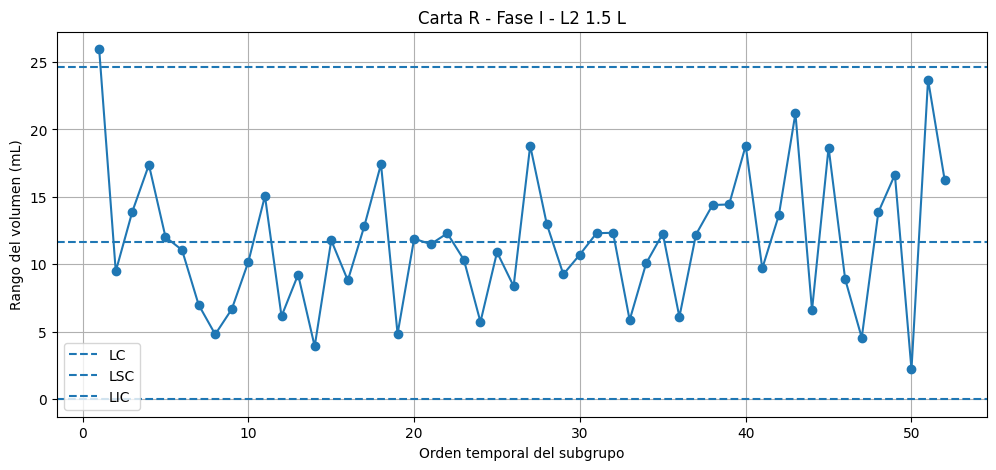

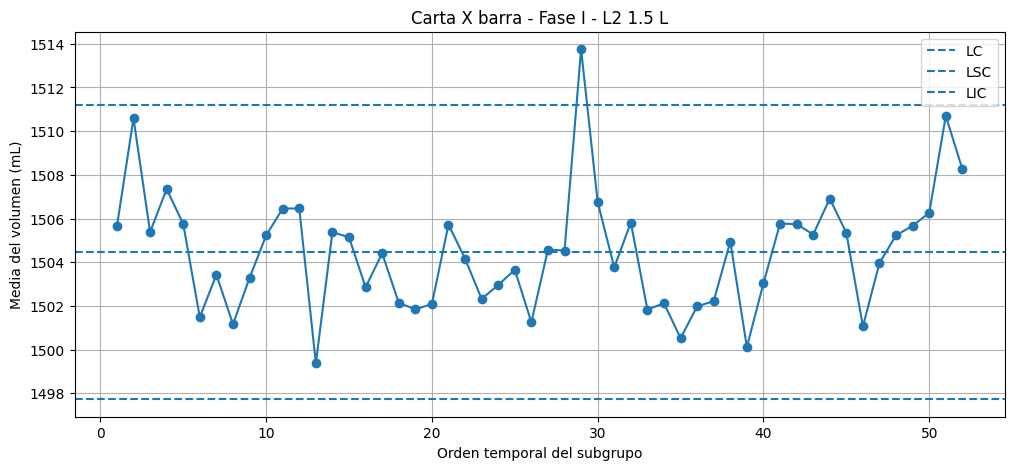

In [27]:
analizar_fase1(datos_control, "L2", 1.5)

La carta \(R\) muestra una señal puntual de variabilidad: el subgrupo 33 tiene \(R=25,95\) mL, superior al \(LSC_R=24,645\) mL. En cambio, la carta \(\bar X\) tiene dos tipos de señales: el subgrupo 129 está directamente sobre el límite superior, y además existe una secuencia de seis medias consecutivas con tendencia.

In [28]:
# Crear nuevamente la Fase I de L2 - 1.5 L
fase1_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_15 = fase1_L2_15.sort_values("subgrupo")
fase1_L2_15["orden"] = range(1, len(fase1_L2_15) + 1)


# Subgrupos que presentaron señales
subgrupos_senal_15 = [
    33, 129,
    158, 159, 160, 165, 166, 167
]


# Recuperar SKU y hora desde los datos originales
info_subgrupo = llenado[
    ["subgrupo", "sku", "hora"]
].drop_duplicates()


# Filtrar solo los subgrupos señalados
diagnostico_15 = fase1_L2_15[
    fase1_L2_15["subgrupo"].isin(subgrupos_senal_15)
].copy()


# Agregar SKU y hora
diagnostico_15 = pd.merge(
    diagnostico_15,
    info_subgrupo,
    on="subgrupo",
    how="left"
)


# Mostrar información relevante
display(
    diagnostico_15[
        [
            "orden",
            "subgrupo",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,orden,subgrupo,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,1,33,1,C (22-06),NEC-D15,22:00,1505.642,25.95
1,29,129,2,C (22-06),NEC-D15,22:00,1513.752,9.26
2,46,158,2,A (06-14),FUN-B15,08:00,1501.064,8.90
3,47,159,2,A (06-14),FUN-B15,10:00,1503.966,4.56
4,48,160,2,A (06-14),FUN-B15,12:00,1505.232,13.86
5,49,165,2,C (22-06),FUN-B15,22:00,1505.674,16.65
6,50,166,2,C (22-06),FUN-B15,00:00,1506.258,2.21
7,51,167,2,C (22-06),FUN-B15,02:00,1510.700,23.70


El diagnóstico de las señales mostró dos comportamientos diferenciados. Los subgrupos 33 y 129 corresponden al SKU NEC-D15, fueron registrados durante el turno C a las 22:00 y pertenecen a semanas distintas, lo que sugiere investigar una posible condición asociada al inicio del turno nocturno o al ajuste de la línea para dicho SKU. Por otra parte, la tendencia detectada en la carta \(\bar X\) corresponde íntegramente al SKU FUN-B15 durante la semana 2. Las medias aumentan progresivamente desde 1501,064 hasta 1510,700 mL. Como la secuencia comprende tanto el turno A como el turno C, la señal no puede atribuirse exclusivamente a un turno y resulta más consistente con un comportamiento temporal asociado al SKU o a las condiciones de operación durante su producción.

PROCESO: L2 - 3.0 L
Cantidad de subgrupos: 68

Carta R
LIC: 0.0
LC: 18.49999999999996
LSC: 39.10899999999992

Carta X barra
LIC: 2998.0858529411767
LC: 3008.7603529411767
LSC: 3019.434852941177

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[56, 57, 58, 59, 60, 65]]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
56,57,3023.588,21.08,L2,3.0,C (22-06),1,I,21


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[79, 80, 81, 82, 83, 84]]


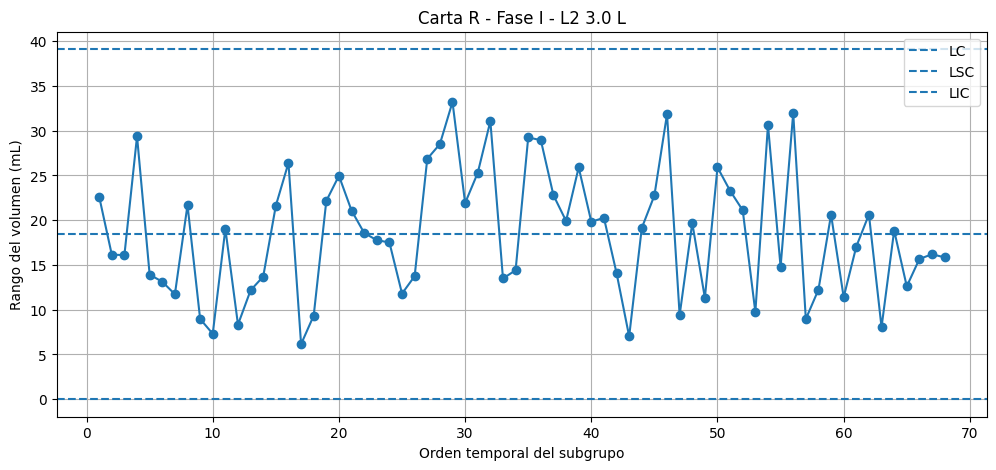

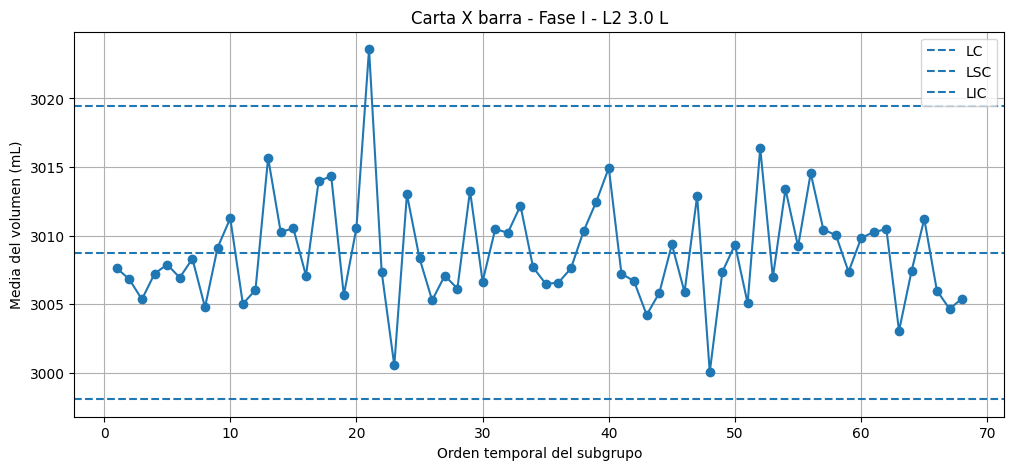

In [29]:
analizar_fase1(datos_control, "L2", 3.0)

Se analizaron los subgrupos identificados mediante las cartas de control y las reglas de Nelson durante la Fase I. Se revisaron sus medias y rangos, junto con las variables fecha, semana, turno, SKU y hora de registro, con el propósito de caracterizar las señales detectadas e identificar posibles asociaciones con las condiciones de operación

In [30]:
# DIAGNÓSTICO DE SEÑALES - L2 3.0 L

# 1. Recuperar los subgrupos de Fase I
fase1_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_30 = fase1_L2_30.sort_values("subgrupo")

# 2. Identificar los subgrupos con señales
subgrupos_senal_30 = [
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

# 3. Recuperar fecha, SKU y hora
info_subgrupo = llenado[
    ["subgrupo", "fecha", "sku", "hora"]
].drop_duplicates()

# 4. Seleccionar solamente los subgrupos señalados
diagnostico_30 = fase1_L2_30[
    fase1_L2_30["subgrupo"].isin(subgrupos_senal_30)
].copy()

# 5. Incorporar la información original
diagnostico_30 = pd.merge(
    diagnostico_30,
    info_subgrupo,
    on="subgrupo",
    how="left"
)

# 6. Mostrar resultados
display(
    diagnostico_30[
        [
            "subgrupo",
            "fecha",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,subgrupo,fecha,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,56,2026-07-22,1,B (14-22),FUN-B30,20:00,3010.568,24.97
1,57,2026-07-22,1,C (22-06),FUN-B30,22:00,3023.588,21.08
2,58,2026-07-22,1,C (22-06),FUN-B30,00:00,3007.366,18.58
3,59,2026-07-22,1,C (22-06),FUN-B30,02:00,3000.548,17.77
4,60,2026-07-22,1,C (22-06),FUN-B30,04:00,3013.016,17.52
5,65,2026-07-23,1,B (14-22),NEC-D30,14:00,3008.356,11.80
6,79,2026-07-24,1,B (14-22),NEC-D30,18:00,3006.496,29.25
7,80,2026-07-24,1,B (14-22),NEC-D30,20:00,3006.574,28.95
8,81,2026-07-24,1,C (22-06),NEC-D30,22:00,3007.624,22.79
9,82,2026-07-24,1,C (22-06),NEC-D30,00:00,3010.328,19.92


Durante la Fase I del proceso L2–3,0 L se identificaron señales de comportamiento no aleatorio tanto en la dispersión como en el nivel medio de llenado.

En la carta R se detectó una tendencia decreciente de seis subgrupos consecutivos, cuyos rangos disminuyeron desde 24,97 hasta 11,80 mL. Esta secuencia comprende principalmente el SKU FUN-B30, finalizando con NEC-D30, por lo que podría estar relacionada con cambios en las condiciones operacionales o en el producto procesado.

En la carta X̄ se identificó al subgrupo 57 con una media de 3.023,588 mL, superior al límite de control de 3.019,435 mL. Además, se detectó una tendencia creciente de seis medias consecutivas, desde 3.006,496 hasta 3.014,944 mL, correspondientes al SKU NEC-D30 durante la semana 1.

Las señales sugieren posibles variaciones asociadas a ajustes del equipo, condiciones de operación o cambios de SKU. Sin embargo, la información disponible no permite establecer una causa asignable definitiva, por lo que las observaciones se conservan y las señales se documentan para su evaluación posterior.

no tenemos evidencia suficiente para afirmar que el proceso estuvo completamente bajo control estadístico durante las semanas 1 y 2


In [31]:
# BLOQUE: RESUMEN DE SEÑALES DETECTADAS EN FASE I

# Crear tabla resumen con las señales identificadas

resumen_fase1 = pd.DataFrame({

    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L"
    ],

    "Carta": [
        "R", "R", "X barra", "X barra",
        "R", "X barra", "X barra"
    ],

    "Regla": [
        "Fuera de límites",
        "Fuera de límites",
        "Fuera de límites",
        "Tendencia 6 puntos",
        "Tendencia 6 puntos",
        "Fuera de límites",
        "Tendencia 6 puntos"
    ],

    "Subgrupos": [
        "92",
        "33",
        "129",
        "158, 159, 160, 165, 166, 167",
        "56, 57, 58, 59, 60, 65",
        "57",
        "79, 80, 81, 82, 83, 84"
    ],

    "Posible causa": [
        "Variación puntual del llenado",
        "Dispersión elevada en turno C",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de FUN-B15",
        "Cambio gradual de variabilidad entre SKU",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de NEC-D30"
    ],

    "Causa confirmada": [
        "No", "No", "No", "No",
        "No", "No", "No"
    ],

    "Decisión": [
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar"
    ]
})

display(resumen_fase1)

,Proceso,Carta,Regla,Subgrupos,Posible causa,Causa confirmada,Decisión
0,L1 - 0.5 L,R,Fuera de límites,92,Variación puntual del llenado,No,Conservar y documentar
1,L2 - 1.5 L,R,Fuera de límites,33,Dispersión elevada en turno C,No,Conservar y documentar
2,L2 - 1.5 L,X barra,Fuera de límites,129,Posible ajuste al inicio del turno C,No,Conservar y documentar
3,L2 - 1.5 L,X barra,Tendencia 6 puntos,"158, 159, 160, 165, 166, 167",Posible deriva durante producción de FUN-B15,No,Conservar y documentar
4,L2 - 3.0 L,R,Tendencia 6 puntos,"56, 57, 58, 59, 60, 65",Cambio gradual de variabilidad entre SKU,No,Conservar y documentar
5,L2 - 3.0 L,X barra,Fuera de límites,57,Posible ajuste al inicio del turno C,No,Conservar y documentar
6,L2 - 3.0 L,X barra,Tendencia 6 puntos,"79, 80, 81, 82, 83, 84",Posible deriva durante producción de NEC-D30,No,Conservar y documentar


Se consolidaron las señales identificadas mediante las cartas \(\bar X-R\) y las reglas de Nelson para las tres combinaciones línea–formato. La tabla permite comparar los comportamientos anormales detectados, identificar los subgrupos involucrados y registrar las posibles causas operacionales. Las hipótesis planteadas no se consideran causas asignables confirmadas, por lo que los registros se mantienen en la base original.

Ahora hay que distinguir las señales estadísticas de posibles errores en los datos

In [32]:
# BLOQUE: VERIFICACIÓN DE DATOS EN SUBGRUPOS SEÑALADOS

# Reunir los identificadores de todos los subgrupos señalados
subgrupos_senalados = [
    92, 33, 129,
    158, 159, 160, 165, 166, 167,
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

revision_datos = []

for sg in sorted(set(subgrupos_senalados)):

    datos_sg = llenado[
        llenado["subgrupo"] == sg
    ]

    # Cantidad de mediciones
    cantidad = len(datos_sg)

    # Revisar faltantes
    faltantes = datos_sg.isnull().sum().sum()

    # Revisar observaciones numeradas 1 a 5
    numeracion_correcta = (
        sorted(datos_sg["n_obs"].tolist()) == [1, 2, 3, 4, 5]
    )

    # Revisar consistencia del formato
    formato_correcto = datos_sg["formato_L"].nunique() == 1

    # Revisar volúmenes válidos
    volumen_positivo = (datos_sg["volumen_mL"] > 0).all()

    revision_datos.append({
        "subgrupo": sg,
        "mediciones": cantidad,
        "faltantes": faltantes,
        "numeracion_correcta": numeracion_correcta,
        "formato_consistente": formato_correcto,
        "volumen_positivo": volumen_positivo
    })

tabla_verificacion = pd.DataFrame(revision_datos)

display(tabla_verificacion)

,subgrupo,mediciones,faltantes,numeracion_correcta,formato_consistente,volumen_positivo
0,33,5,0,True,True,True
1,56,5,0,True,True,True
2,57,5,0,True,True,True
3,58,5,0,True,True,True
4,59,5,0,True,True,True
5,60,5,0,True,True,True
6,65,5,0,True,True,True
7,79,5,0,True,True,True
8,80,5,0,True,True,True
9,81,5,0,True,True,True


Verificación de integridad de los subgrupos señalados
Se revisaron las mediciones individuales de los subgrupos que presentaron señales estadísticas durante la Fase I, con el objetivo de identificar posibles problemas de registro, valores faltantes o inconsistencias respecto del formato de envase. Esta revisión permite diferenciar anomalías estadísticas de posibles errores de datos, evitando excluir observaciones válidas sin una justificación técnica.

Ahora nos preguntamos ¿Los subgrupos del turno C presentan, en general, medias o rangos mayores que los otros turnos dentro del mismo proceso?

In [33]:
# BLOQUE: EVALUACIÓN DE POSIBLES CAUSAS - TURNOS

# Seleccionar únicamente Fase I
datos_fase1 = datos_control[
    datos_control["fase"] == "I"
].copy()

# Comparar media y rango por proceso y turno
comparacion_turnos = datos_fase1.groupby(
    ["linea", "formato_L", "turno"]
)[["media_volumen", "rango_volumen"]].agg(
    ["count", "mean"]
)

print("Comparación de procesos según turno:")
display(comparacion_turnos)

Comparación de procesos según turno:


media_volumen              rango_volumen           
                                  count         mean         count       mean
linea formato_L turno                                                        
L1    0.5       A (06-14)            24   502.431750            24   4.237917
                B (14-22)            24   502.855500            24   5.261250
L2    1.5       A (06-14)            28  1503.083500            28  10.247857
                B (14-22)             4  1502.581500             4  14.962500
                C (22-06)            20  1506.754200            20  12.971500
      3.0       A (06-14)            12  3009.026500            12  17.616667
                B (14-22)            36  3007.904389            36  16.690556
                C (22-06)            20  3010.141400            20  22.287000

Una vez verificada la integridad básica de los subgrupos señalados, se procedió a contrastar las anomalías estadísticas con las condiciones de operación. Se analizaron las diferencias en el nivel medio y la dispersión del volumen según línea, formato y turno durante la Fase I, con el objetivo de identificar posibles asociaciones entre las señales detectadas y las características del proceso productivo.

Este análisis es exploratorio y permite formular hipótesis operacionales, sin establecer relaciones causales definitivas.

Proceso	Hallazgo principal
L1–0,5 L	El turno B tiene mayor rango promedio (5,26 mL) que A (4,24 mL).
L2–1,5 L	El turno C presenta la media más alta (1.506,75 mL).
L2–3,0 L	El turno C presenta tanto la media más alta (3.010,14 mL) como el rango promedio más alto (22,29 mL).

**DECISION PARA FASE 2!!!!!:**
Después de revisar las anomalías detectadas en los tres procesos, comprobamos que los subgrupos tenían sus cinco mediciones, no presentaban datos faltantes y cumplían las verificaciones básicas realizadas.

Aunque encontramos valores fuera de los límites de control y algunas tendencias, no logramos identificar una causa específica que permitiera justificar la eliminación de esos registros.

Por esta razón, decidimos conservar todos los datos y mantener los límites calculados inicialmente, evitando modificar los resultados sin una justificación.

Sin embargo, como se detectaron señales de comportamiento anormal, todavía no podemos afirmar que los procesos sean completamente estables. Por lo tanto, utilizaremos estos límites de manera provisional para analizar las semanas siguientes (Fase II), dejando constancia de esta limitación.

In [34]:
# BLOQUE: DECISIÓN SOBRE LÍMITES DE FASE I

decision_limites = pd.DataFrame({
    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L"
    ],

    "Subgrupos_Fase_I": [
        48, 52, 68
    ],

    "Causa_asignable_confirmada": [
        "No", "No", "No"
    ],

    "Exclusiones": [
        0, 0, 0
    ],

    "Decision": [
        "Conservar límites preliminares",
        "Conservar límites preliminares",
        "Conservar límites preliminares"
    ],

    "Estado": [
        "Estabilidad no demostrada",
        "Estabilidad no demostrada",
        "Estabilidad no demostrada"
    ]
})

display(decision_limites)

,Proceso,Subgrupos_Fase_I,Causa_asignable_confirmada,Exclusiones,Decision,Estado
0,L1 - 0.5 L,48,No,0,Conservar límites preliminares,Estabilidad no demostrada
1,L2 - 1.5 L,52,No,0,Conservar límites preliminares,Estabilidad no demostrada
2,L2 - 3.0 L,68,No,0,Conservar límites preliminares,Estabilidad no demostrada


**PREPARACION FASE 2**
Para saber:
Fase I (semanas 1 y 2): calculamos límites, detectamos anomalías e investigamos posibles causas.
Fase II (semanas 3 a 10): evaluaremos si los nuevos subgrupos presentan señales utilizando los mismos límites.


In [35]:
#PREPARACIÓN FASE 2
# BLOQUE: GUARDAR LÍMITES DE FASE I

# Constantes para subgrupos de 5 botellas
A2 = 0.577
D3 = 0
D4 = 2.114

limites_fase1 = []

# Procesos que estamos analizando
procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

for linea, formato in procesos:

    # Seleccionar únicamente los subgrupos de Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ]

    # Promedio de medias y rangos
    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Guardar límites de ambas cartas
    limites_fase1.append({
        "linea": linea,
        "formato_L": formato,
        "LIC_R": D3 * media_rangos,
        "LC_R": media_rangos,
        "LSC_R": D4 * media_rangos,
        "LIC_X": media_medias - A2 * media_rangos,
        "LC_X": media_medias,
        "LSC_X": media_medias + A2 * media_rangos
    })

limites_fase1 = pd.DataFrame(limites_fase1)

display(limites_fase1.round(3))

,linea,formato_L,LIC_R,LC_R,LSC_R,LIC_X,LC_X,LSC_X
0,L1,0.5,0.0,4.750,10.041,499.903,502.644,505.384
1,L2,1.5,0.0,11.658,24.645,1497.730,1504.457,1511.183
2,L2,3.0,0.0,18.500,39.109,2998.086,3008.760,3019.435


Preparación de la Fase II

Para evaluar el comportamiento del llenado durante las semanas 3 a 10, se utilizarán los límites preliminares obtenidos en Fase I (semanas 1 y 2). Estos límites se mantendrán constantes durante el monitoreo, evitando recalcularlos con las nuevas observaciones.

Debido a las señales detectadas durante Fase I, los resultados de Fase II se interpretarán como una evaluación provisional del proceso.

In [36]:
# BLOQUE: SELECCIÓN DE DATOS PARA FASE II

fase2 = datos_control[
    datos_control["fase"] == "II"
].copy()

# Revisar cantidad total de subgrupos
print("Total de subgrupos en Fase II:")
print(fase2.shape[0])

# Revisar distribución por proceso
print("\nSubgrupos por línea y formato:")
print(
    fase2.groupby(["linea", "formato_L"]).size()
)

Total de subgrupos en Fase II:
672

Subgrupos por línea y formato:
linea  formato_L
L1     0.5          192
L2     1.5          236
       3.0          244
dtype: int64


Selección de datos para Fase II

Para desarrollar el monitoreo de Fase II se seleccionaron los subgrupos correspondientes a las semanas 3 a 10. Estos datos se evaluarán utilizando los límites preliminares obtenidos durante las semanas 1 y 2, sin modificarlos ni recalcularlos con las nuevas observaciones.

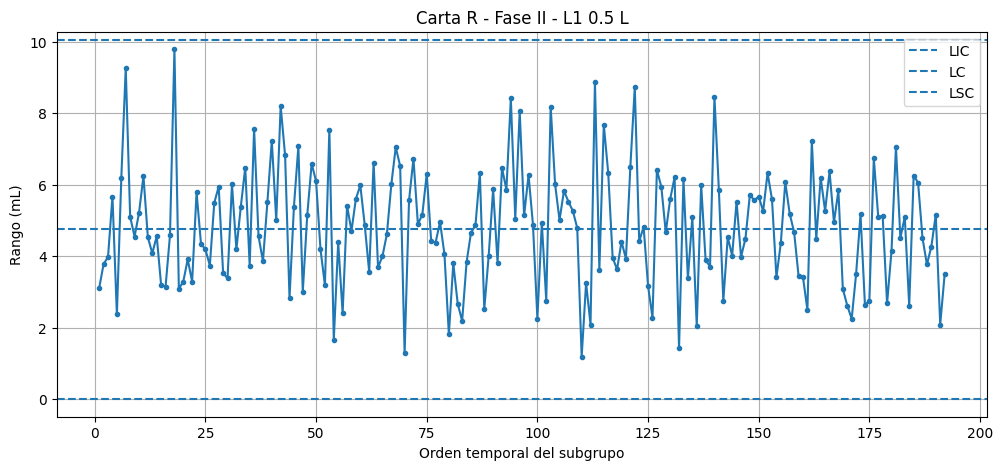

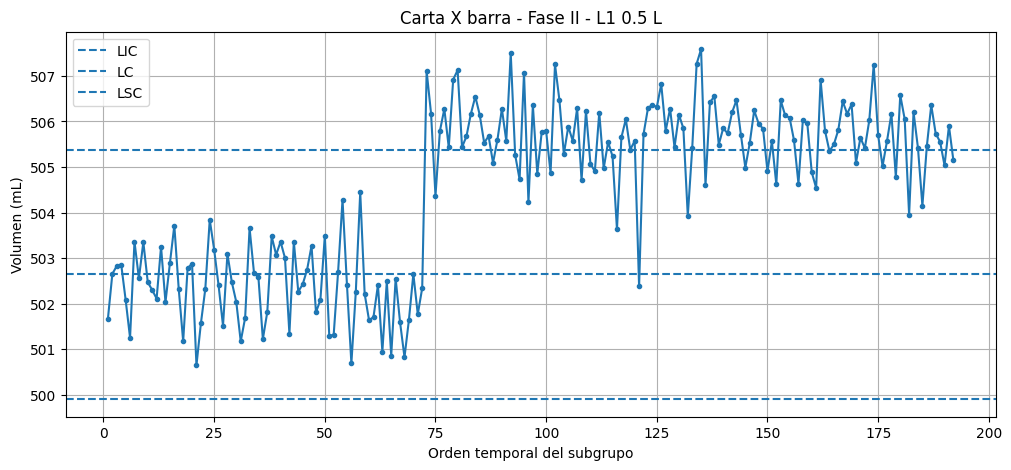

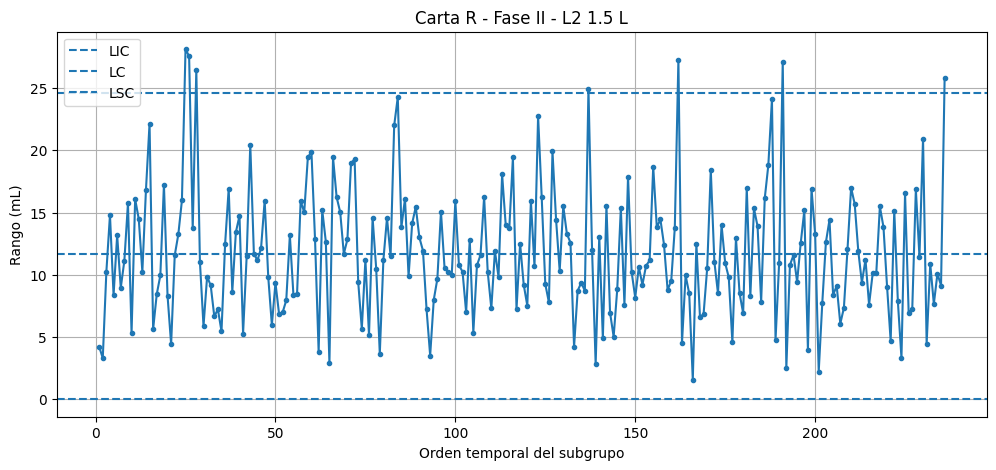

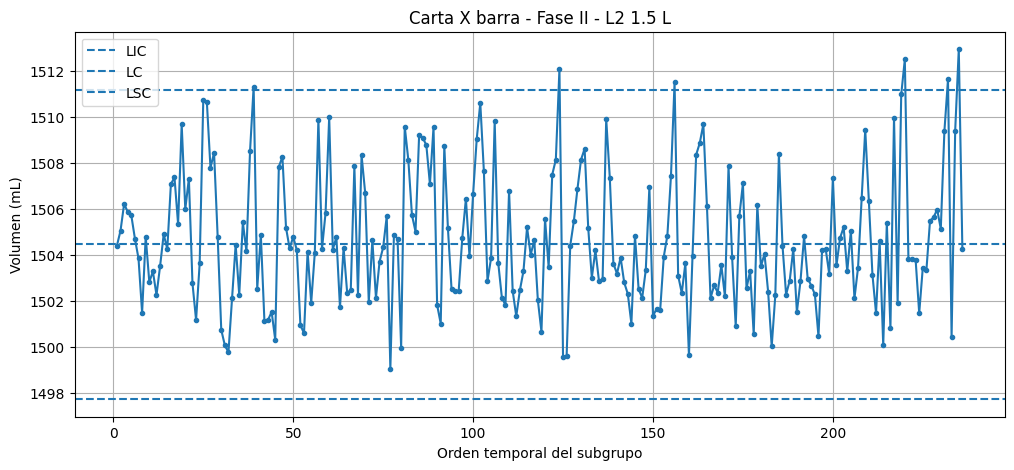

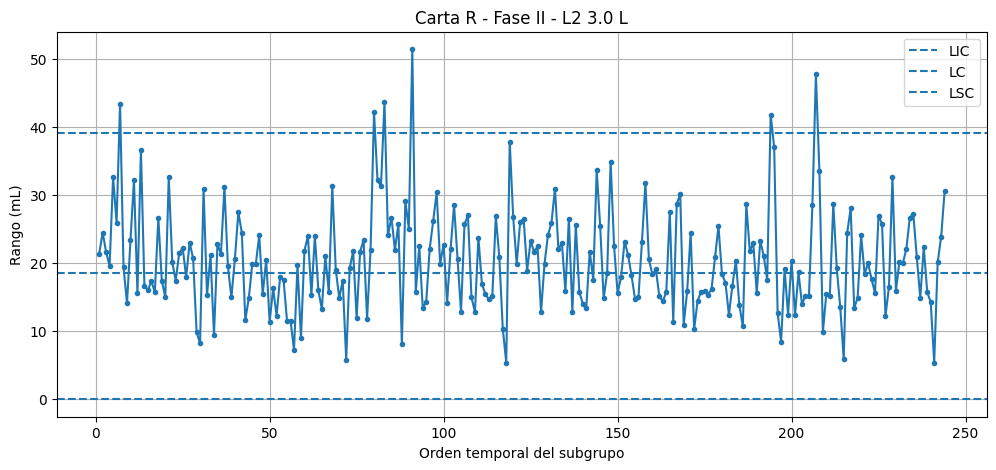

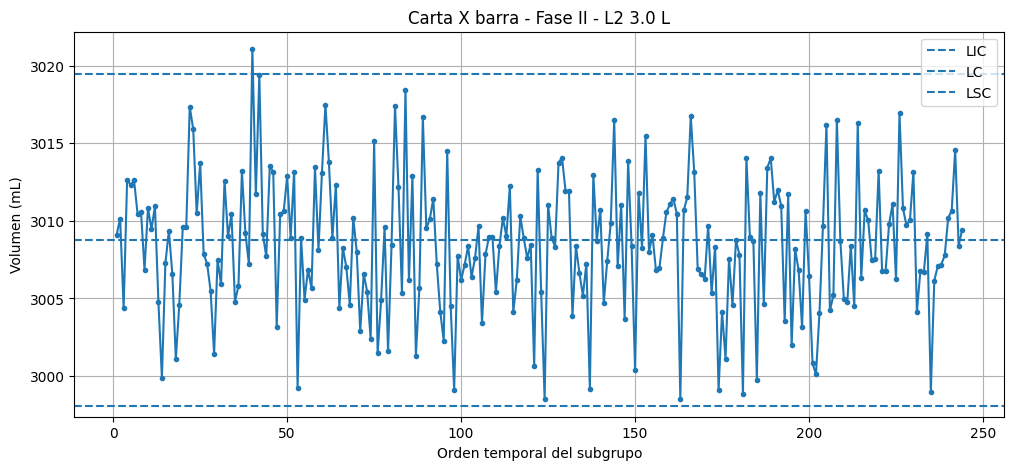

In [37]:
# BLOQUE: CARTAS DE CONTROL - FASE II


def graficar_fase2(linea, formato):

    # Seleccionar el proceso en Fase II
    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ].copy()

    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Recuperar los límites calculados en Fase I
    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    # Graficar ambas cartas
    for variable, nombre, tipo in [
        ("rango_volumen", "R", "R"),
        ("media_volumen", "X barra", "X")
    ]:

        LIC = limites["LIC_" + tipo]
        LC = limites["LC_" + tipo]
        LSC = limites["LSC_" + tipo]

        plt.figure(figsize=(12, 5))

        plt.plot(
            datos["orden"],
            datos[variable],
            marker="o",
            markersize=3
        )

        plt.axhline(LIC, linestyle="--", label="LIC")
        plt.axhline(LC, linestyle="--", label="LC")
        plt.axhline(LSC, linestyle="--", label="LSC")

        plt.xlabel("Orden temporal del subgrupo")
        plt.ylabel("Volumen (mL)" if tipo == "X" else "Rango (mL)")
        plt.title(
            "Carta " + nombre + " - Fase II - " +
            linea + " " + str(formato) + " L"
        )

        plt.legend()
        plt.grid()
        plt.show()



# Ejecutar las cartas de Fase II para los tres procesos

graficar_fase2("L1", 0.5)

graficar_fase2("L2", 1.5)

graficar_fase2("L2", 3.0)

### Análisis de las cartas de control – Fase II

Una vez terminada la revisión de la Fase I, se comenzó el análisis de la Fase II, utilizando los datos correspondientes a las semanas 3 a 10. En esta etapa se analizaron 672 subgrupos, distribuidos entre los tres procesos de llenado: L1–0,5 L (192 subgrupos), L2–1,5 L (236 subgrupos) y L2–3,0 L (244 subgrupos).

El objetivo de esta etapa es evaluar si el comportamiento del proceso de llenado se mantiene similar al observado durante las primeras dos semanas. Para ello, se utilizaron los límites de control calculados en la Fase I, manteniéndolos sin modificaciones.

Es importante recordar que durante la Fase I se detectaron algunas señales de comportamiento anormal que no pudieron asociarse a causas confirmadas. Por esta razón, los límites utilizados son provisionales y los resultados de esta segunda etapa deben interpretarse considerando esa limitación.

**¿Qué representan los gráficos?**

Para cada combinación de línea y formato se construyeron dos cartas de control:

**1. Carta R: análisis de la variabilidad**

Esta carta permite observar cuánto varía el volumen entre las cinco botellas de un mismo subgrupo.

Cada punto del gráfico representa el rango de un subgrupo, calculado como la diferencia entre la botella con mayor volumen y la de menor volumen.

La carta R permite identificar si la dispersión del llenado se mantiene similar a la del período inicial o si aparecen cambios importantes.

Por ejemplo, un punto con un rango elevado significa que las cinco botellas de ese subgrupo presentan diferencias de volumen mayores de lo habitual.

**2. Carta X̄: análisis del promedio de llenado**

Esta carta muestra cómo cambia el volumen promedio de las cinco botellas de cada subgrupo a lo largo del tiempo.

Cada punto representa la media de un subgrupo.

Su objetivo es detectar si el proceso comienza a llenar, en promedio, con cantidades más altas o más bajas que las observadas durante la Fase I.

Por ejemplo, un aumento sostenido de las medias podría indicar que el proceso está entregando progresivamente más producto del esperado.

**¿Qué significan las líneas de los gráficos?**

Ambas cartas tienen tres líneas horizontales:

- **LIC (Límite Inferior de Control):** indica el límite inferior esperado para el comportamiento estadístico del proceso.
- **LC (Línea Central):** representa el valor promedio utilizado como referencia, calculado durante la Fase I.
- **LSC (Límite Superior de Control):** indica el límite superior esperado para el comportamiento estadístico del proceso.

Cuando un punto supera el LSC o queda por debajo del LIC, se identifica una señal de posible causa especial que debe investigarse.

Sin embargo, un proceso también puede presentar comportamientos anormales aunque todos los puntos estén dentro de los límites. Por eso, además de observar los gráficos, se aplicarán las reglas de Nelson seleccionadas anteriormente.

**¿Qué buscamos comprobar en Fase II?**

Buscamos identificar si durante las semanas 3 a 10 aparecen cambios en el promedio o la variabilidad del llenado.

Para ello, se revisarán los puntos fuera de los límites de control, las secuencias de nueve puntos consecutivos al mismo lado de la línea central y las tendencias de seis puntos consecutivos crecientes o decrecientes.

Los resultados permitirán identificar los períodos que requieren mayor atención y relacionar las señales con las condiciones de producción, como el turno, la semana y el SKU.

Es importante señalar que los límites de control no son lo mismo que los límites de especificación del producto. Las cartas permiten estudiar la estabilidad estadística del proceso, mientras que el cumplimiento de las especificaciones se evaluará posteriormente mediante el análisis de capacidad.

In [38]:
# BLOQUE: REGLAS DE NELSON - FASE II

def detectar_senales(datos, columna, carta, limites, proceso):

    valores = datos[columna].tolist()
    subgrupos = datos["subgrupo"].tolist()

    LIC = limites["LIC_" + carta]
    LC = limites["LC_" + carta]
    LSC = limites["LSC_" + carta]

    senales = []

    # Regla 1: puntos fuera de límites
    for i in range(len(valores)):

        if valores[i] > LSC or valores[i] < LIC:
            senales.append([
                proceso, carta, "Fuera de límites",
                str(subgrupos[i])
            ])

    # Regla 2: 9 puntos al mismo lado de LC
    for i in range(len(valores) - 8):

        grupo = valores[i:i+9]

        arriba = all(x > LC for x in grupo)
        abajo = all(x < LC for x in grupo)

        if arriba or abajo:
            senales.append([
                proceso, carta, "9 puntos mismo lado",
                str(subgrupos[i:i+9])
            ])

    # Regla 3: tendencia de 6 puntos
    for i in range(len(valores) - 5):

        grupo = valores[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1] for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1] for j in range(5)
        )

        if creciente or decreciente:
            senales.append([
                proceso, carta, "Tendencia 6 puntos",
                str(subgrupos[i:i+6])
            ])

    return senales


# Aplicar las reglas a los tres procesos
resultados = []

for linea, formato in [("L1", 0.5), ("L2", 1.5), ("L2", 3.0)]:

    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ].sort_values(["semana_registro", "subgrupo"])

    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    proceso = linea + " - " + str(formato) + " L"

    resultados += detectar_senales(
        datos, "rango_volumen", "R", limites, proceso
    )

    resultados += detectar_senales(
        datos, "media_volumen", "X", limites, proceso
    )


# Crear tabla con los resultados
senales_fase2 = pd.DataFrame(
    resultados,
    columns=["Proceso", "Carta", "Regla", "Subgrupos"]
)

print("Señales detectadas en Fase II:")
display(senales_fase2)

Señales detectadas en Fase II:


,Proceso,Carta,Regla,Subgrupos
0,L1 - 0.5 L,R,Tendencia 6 puntos,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,421
2,L1 - 0.5 L,X,Fuera de límites,422
3,L1 - 0.5 L,X,Fuera de límites,424
4,L1 - 0.5 L,X,Fuera de límites,425
...,...,...,...,...
222,L2 - 3.0 L,X,9 puntos mismo lado,"[641, 642, 643, 644, 645, 646, 647, 648, 649]"
223,L2 - 3.0 L,X,Tendencia 6 puntos,"[572, 577, 578, 579, 580, 613]"
224,L2 - 3.0 L,X,Tendencia 6 puntos,"[823, 824, 829, 830, 831, 832]"
225,L2 - 3.0 L,X,Tendencia 6 puntos,"[824, 829, 830, 831, 832, 833]"


In [39]:


print("L1 - 0.5 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L1 - 0.5 L"
    ]
)

print("L2 - 1.5 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L2 - 1.5 L"
    ]
)

print("L2 - 3.0 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L2 - 3.0 L"
    ]
)

L1 - 0.5 L


,Proceso,Carta,Regla,Subgrupos
0,L1 - 0.5 L,R,Tendencia 6 puntos,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,421
2,L1 - 0.5 L,X,Fuera de límites,422
3,L1 - 0.5 L,X,Fuera de límites,424
4,L1 - 0.5 L,X,Fuera de límites,425
...,...,...,...,...
190,L1 - 0.5 L,X,9 puntos mismo lado,"[768, 769, 770, 771, 772, 773, 774, 775, 776]"
191,L1 - 0.5 L,X,9 puntos mismo lado,"[769, 770, 771, 772, 773, 774, 775, 776, 777]"
192,L1 - 0.5 L,X,9 puntos mismo lado,"[770, 771, 772, 773, 774, 775, 776, 777, 778]"
193,L1 - 0.5 L,X,9 puntos mismo lado,"[771, 772, 773, 774, 775, 776, 777, 778, 779]"


L2 - 1.5 L


,Proceso,Carta,Regla,Subgrupos
195,L2 - 1.5 L,R,Fuera de límites,249
196,L2 - 1.5 L,R,Fuera de límites,250
197,L2 - 1.5 L,R,Fuera de límites,252
198,L2 - 1.5 L,R,Fuera de límites,585
199,L2 - 1.5 L,R,Fuera de límites,670
200,L2 - 1.5 L,R,Fuera de límites,735
201,L2 - 1.5 L,R,Fuera de límites,840
202,L2 - 1.5 L,X,Fuera de límites,287
203,L2 - 1.5 L,X,Fuera de límites,564
204,L2 - 1.5 L,X,Fuera de límites,636


L2 - 3.0 L


,Proceso,Carta,Regla,Subgrupos
212,L2 - 3.0 L,R,Fuera de límites,203
213,L2 - 3.0 L,R,Fuera de límites,392
214,L2 - 3.0 L,R,Fuera de límites,395
215,L2 - 3.0 L,R,Fuera de límites,407
216,L2 - 3.0 L,R,Fuera de límites,666
217,L2 - 3.0 L,R,Fuera de límites,719
218,L2 - 3.0 L,R,9 puntos mismo lado,"[391, 392, 393, 394, 395, 396, 397, 398, 399]"
219,L2 - 3.0 L,R,9 puntos mismo lado,"[479, 480, 481, 482, 483, 484, 493, 494, 495]"
220,L2 - 3.0 L,X,Fuera de límites,300
221,L2 - 3.0 L,X,9 puntos mismo lado,"[640, 641, 642, 643, 644, 645, 646, 647, 648]"


Se aplicaron las tres reglas de Nelson utilizadas anteriormente para detectar posibles anomalías durante la Fase II. El análisis se realizó por separado para cada línea y formato, utilizando los límites establecidos en Fase I, con el objetivo de identificar cambios en la variabilidad y en el promedio de llenado.
*resultado** : los gráficos nos permitieron observar cómo se comportó el llenado y las reglas de Nelson nos ayudaron a detectar posibles cambios. Ahora tenemos que organizar e investigar esas señales para completar correctamente la Fase II.

In [40]:
# Resumen de las señales detectadas en Fase II

resumen_senales_fase2 = (
    senales_fase2
    .groupby(["Proceso", "Carta", "Regla"])
    .size()
    .reset_index(name="Cantidad de detecciones")
)

display(resumen_senales_fase2)

,Proceso,Carta,Regla,Cantidad de detecciones
0,L1 - 0.5 L,R,Tendencia 6 puntos,1
1,L1 - 0.5 L,X,9 puntos mismo lado,106
2,L1 - 0.5 L,X,Fuera de límites,88
3,L2 - 1.5 L,R,Fuera de límites,7
4,L2 - 1.5 L,X,9 puntos mismo lado,1
5,L2 - 1.5 L,X,Fuera de límites,6
6,L2 - 1.5 L,X,Tendencia 6 puntos,3
7,L2 - 3.0 L,R,9 puntos mismo lado,2
8,L2 - 3.0 L,R,Fuera de límites,6
9,L2 - 3.0 L,X,9 puntos mismo lado,2


La tabla nos muestra cuantas veces se activo cada regla de nelson durante la fase 2,
### Resultados de las reglas de Nelson – Fase II

Al aplicar las reglas de Nelson se identificaron distintas señales de posibles cambios en los procesos de llenado. El resultado más destacado corresponde a L1–0,5 L, donde 88 de los 192 subgrupos presentaron promedios fuera de los límites de control. En L2–1,5 L y L2–3,0 L también se detectaron señales relacionadas con el promedio y la variabilidad.

Estos resultados requieren una revisión por semana, turno y SKU para investigar posibles causas. Además, algunas secuencias detectadas se superponen, por lo que no deben contarse como anomalías independientes.

In [41]:
# Revisar puntos fuera de límites por semana

revision = fase2.merge(
    limites_fase1,
    on=["linea", "formato_L"]
)

revision["fuera_X"] = (
    (revision["media_volumen"] < revision["LIC_X"]) |
    (revision["media_volumen"] > revision["LSC_X"])
)

revision["fuera_R"] = (
    (revision["rango_volumen"] < revision["LIC_R"]) |
    (revision["rango_volumen"] > revision["LSC_R"])
)

resumen_semanal = revision.groupby(
    ["linea", "formato_L", "semana_registro"]
)[["fuera_X", "fuera_R"]].sum()

display(resumen_semanal)

fuera_X  fuera_R
linea formato_L semana_registro                  
L1    0.5       3                      0        0
                4                      0        0
                5                      0        0
                6                     19        0
                7                     14        0
                8                     21        0
                9                     17        0
                10                    17        0
L2    1.5       3                      0        3
                4                      1        0
                5                      0        0
                6                      0        0
                7                      1        1
                8                      1        1
                9                      0        1
                10                     3        1
      3.0       3                      0        1
                4                      1        0
                5                      0        3
                6                      0        0
                7                      0        0
                8                      0        1
                9                      0        1
                10                     0        0

**### Análisis de las señales por semana – Fase II**

Al revisar las señales por semana, se observó que el proceso L1–0,5 L presenta el cambio más importante. Durante las semanas 3 a 5 no se detectaron promedios fuera de límites, pero desde la semana 6 comenzaron a aparecer numerosas señales, alcanzando un total de 88 subgrupos.

En los procesos L2–1,5 L y L2–3,0 L también se identificaron puntos fuera de límites, aunque en menor cantidad y distribuidos entre distintas semanas.

Estos resultados indican posibles cambios en el comportamiento del llenado que requieren una revisión más detallada para investigar sus causas.

In [42]:
# Revisar las señales de L1 - 0.5 L

l1_fuera = revision[
    (revision["linea"] == "L1") &
    (revision["formato_L"] == 0.5) &
    (revision["fuera_X"])
].copy()

# Identificar si el promedio quedó arriba o abajo
l1_fuera["direccion"] = "Bajo el LIC"

l1_fuera.loc[
    l1_fuera["media_volumen"] > l1_fuera["LSC_X"],
    "direccion"
] = "Sobre el LSC"

# Contar señales por semana, turno y dirección
resumen_l1 = (
    l1_fuera
    .groupby(["semana_registro", "turno", "direccion"])
    .size()
    .reset_index(name="Cantidad")
)

display(resumen_l1)

,semana_registro,turno,direccion,Cantidad
0,6,A (06-14),Sobre el LSC,11
1,6,B (14-22),Sobre el LSC,8
2,7,A (06-14),Sobre el LSC,7
3,7,B (14-22),Sobre el LSC,7
4,8,A (06-14),Sobre el LSC,10
5,8,B (14-22),Sobre el LSC,11
6,9,A (06-14),Sobre el LSC,9
7,9,B (14-22),Sobre el LSC,8
8,10,A (06-14),Sobre el LSC,9
9,10,B (14-22),Sobre el LSC,8


**Revisión de las señales del proceso L1–0,5 L**

Al analizar los 88 subgrupos con promedios fuera de control, se observó que todos superaron el límite superior. Estas señales comenzaron en la semana 6 y continuaron hasta la semana 10.

Además, se presentaron en ambos turnos: 46 detecciones en el turno A y 42 en el turno B. Esto sugiere un posible aumento sostenido del promedio de llenado, cuya causa todavía debe investigarse.

Los resultados se interpretan considerando que los límites de Fase I son provisionales.

In [43]:
# Revisar los nombres de las columnas de los datos originales
print(llenado.columns.tolist())

['subgrupo', 'fecha', 'semana_registro', 'turno', 'linea', 'sku', 'formato_L', 'hora', 'n_obs', 'volumen_mL']


In [44]:
# ANALISIS DE LAS SEÑALES POR SKU - L1 0.5 L

# Obtener el SKU de cada subgrupo, sin repetir las 5 botellas
sku_subgrupos = llenado[["subgrupo", "sku"]].drop_duplicates()

# Seleccionar L1 - 0.5 L, semanas 6 a 10
datos_l1 = revision[
    (revision["linea"] == "L1") &
    (revision["formato_L"] == 0.5) &
    (revision["semana_registro"] >= 6)
].copy()

# Agregar el SKU correspondiente a cada subgrupo
datos_l1 = datos_l1.merge(
    sku_subgrupos,
    on="subgrupo",
    how="left"
)

# Identificar promedios superiores al límite
datos_l1["sobre_LSC"] = (
    datos_l1["media_volumen"] > datos_l1["LSC_X"]
)

# Resumir los resultados por SKU
resumen_sku = datos_l1.groupby("sku")["sobre_LSC"].agg(
    ["count", "sum"]
).reset_index()

resumen_sku.columns = [
    "SKU", "Subgrupos analizados", "Sobre el LSC"
]

# Calcular el porcentaje de señales
resumen_sku["Porcentaje (%)"] = (
    resumen_sku["Sobre el LSC"] /
    resumen_sku["Subgrupos analizados"] * 100
).round(1)

display(resumen_sku)

,SKU,Subgrupos analizados,Sobre el LSC,Porcentaje (%)
0,CIT-L05,40,33,82.5
1,FUN-B05,32,20,62.5
2,NEC-D05,48,35,72.9


### Análisis de señales según SKU – L1 de 0,5 L

Al revisar las semanas 6 a 10, se observó que los tres SKU presentaron promedios superiores al límite de control. El mayor porcentaje corresponde a CIT-L05 (82,5 %), seguido de NEC-D05 (72,9 %) y FUN-B05 (62,5 %).

En total, 88 de los 120 subgrupos analizados superaron el límite superior de control. Como las señales aparecen en distintos productos y en ambos turnos, podría existir un factor común en el proceso de llenado. Sin embargo, su causa no puede confirmarse únicamente con estos datos.

In [45]:
# Revisar señales por SKU y turno en L2

datos_l2 = revision[
    revision["linea"] == "L2"
].copy()

datos_l2 = datos_l2.merge(
    sku_subgrupos,
    on="subgrupo",
    how="left"
)

resumen_l2 = datos_l2.groupby(
    ["formato_L", "sku", "turno"]
)[["fuera_X", "fuera_R"]].sum()

display(resumen_l2)

fuera_X  fuera_R
formato_L sku     turno                      
1.5       CIT-L15 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        0        1
          FUN-B15 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        3        4
          NEC-D15 A (06-14)        0        1
                  B (14-22)        0        0
                  C (22-06)        3        1
3.0       CIT-L30 A (06-14)        0        0
                  B (14-22)        0        1
                  C (22-06)        0        1
          FUN-B30 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        1        1
          NEC-D30 A (06-14)        0        0
                  B (14-22)        0        1
                  C (22-06)        0        2

**### Análisis de señales por SKU y turno – Línea L2**

En el formato de 1,5 L se identificaron 6 puntos fuera de límites en la carta X̄ y 7 en la carta R, concentrados principalmente en el turno C.

En el formato de 3,0 L se detectó 1 punto fuera de límites en la carta X̄ y 6 en la carta R, con mayor presencia de señales de variabilidad en los turnos B y C.

Estos resultados indican que es necesario revisar las condiciones de producción de dichos turnos. Sin embargo, las señales no permiten confirmar una causa específica.

In [46]:
# Comparar señales según la cantidad producida por turno

comparacion_l2 = datos_l2.groupby(
    ["formato_L", "turno"]
).agg(
    subgrupos=("subgrupo", "count"),
    fuera_X=("fuera_X", "sum"),
    fuera_R=("fuera_R", "sum")
).reset_index()

# Calcular porcentajes
comparacion_l2["porcentaje_X"] = (
    comparacion_l2["fuera_X"] /
    comparacion_l2["subgrupos"] * 100
).round(1)

comparacion_l2["porcentaje_R"] = (
    comparacion_l2["fuera_R"] /
    comparacion_l2["subgrupos"] * 100
).round(1)

display(comparacion_l2)

,formato_L,turno,subgrupos,fuera_X,fuera_R,porcentaje_X,porcentaje_R
0,1.5,A (06-14),80,0,1,0.0,1.2
1,1.5,B (14-22),72,0,0,0.0,0.0
2,1.5,C (22-06),84,6,6,7.1,7.1
3,3.0,A (06-14),80,0,0,0.0,0.0
4,3.0,B (14-22),88,0,2,0.0,2.3
5,3.0,C (22-06),76,1,4,1.3,5.3


Comparación de señales entre turnos – Línea L2

Al comparar los porcentajes de puntos fuera de los límites de control, se observó que el turno C presenta las mayores proporciones de señales en ambos formatos.

En L2–1,5 L, el 7,1 % de los subgrupos del turno C presentó señales tanto en la carta X̄ como en la carta R. En L2–3,0 L, el porcentaje más alto corresponde a la carta R del mismo turno, con un 5,3 %.

Estos resultados sugieren que es necesario investigar las condiciones de producción del turno C, aunque no permiten confirmar que este sea la causa de las variaciones.

In [47]:
# BLOQUE: CONSOLIDAR SEÑALES DE FASE II EN EPISODIOS

def consolidar_eventos(datos, columna, carta, limites, proceso):

    datos = datos.sort_values(
        ["semana_registro", "subgrupo"]
    ).reset_index(drop=True)

    valores = datos[columna].tolist()
    subgrupos = datos["subgrupo"].tolist()

    LIC = limites["LIC_" + carta]
    LC = limites["LC_" + carta]
    LSC = limites["LSC_" + carta]

    eventos = []

    # 1. Puntos fuera de los límites
    estados = []

    for valor in valores:

        if valor > LSC:
            estados.append("Sobre LSC")

        elif valor < LIC:
            estados.append("Bajo LIC")

        else:
            estados.append("Dentro")

    i = 0

    while i < len(valores):

        if estados[i] == "Dentro":
            i += 1
            continue

        estado = estados[i]
        inicio = i

        while (
            i + 1 < len(valores) and
            estados[i + 1] == estado
        ):
            i += 1

        fin = i

        eventos.append({
            "Proceso": proceso,
            "Carta": carta,
            "Regla": "Fuera de límites",
            "Direccion": estado,
            "N_puntos": fin - inicio + 1,
            "Subgrupos": subgrupos[inicio:fin + 1]
        })

        i += 1

    # 2. Racha de 9 o más puntos al mismo lado de LC
    i = 0

    while i < len(valores):

        if valores[i] > LC:
            lado = "Sobre LC"

        elif valores[i] < LC:
            lado = "Bajo LC"

        else:
            i += 1
            continue

        inicio = i
        i += 1

        while i < len(valores):

            if lado == "Sobre LC" and valores[i] > LC:
                i += 1

            elif lado == "Bajo LC" and valores[i] < LC:
                i += 1

            else:
                break

        fin = i - 1
        cantidad = fin - inicio + 1

        if cantidad >= 9:

            eventos.append({
                "Proceso": proceso,
                "Carta": carta,
                "Regla": "Racha mismo lado",
                "Direccion": lado,
                "N_puntos": cantidad,
                "Subgrupos": subgrupos[inicio:fin + 1]
            })

    # 3. Tendencia de 6 o más puntos
    i = 0

    while i < len(valores) - 1:

        if valores[i + 1] > valores[i]:
            direccion = "Creciente"

        elif valores[i + 1] < valores[i]:
            direccion = "Decreciente"

        else:
            i += 1
            continue

        inicio = i
        i += 1

        while i < len(valores) - 1:

            if (
                direccion == "Creciente" and
                valores[i + 1] > valores[i]
            ):
                i += 1

            elif (
                direccion == "Decreciente" and
                valores[i + 1] < valores[i]
            ):
                i += 1

            else:
                break

        fin = i
        cantidad = fin - inicio + 1

        if cantidad >= 6:

            eventos.append({
                "Proceso": proceso,
                "Carta": carta,
                "Regla": "Tendencia",
                "Direccion": direccion,
                "N_puntos": cantidad,
                "Subgrupos": subgrupos[inicio:fin + 1]
            })

    return eventos

In [48]:
# Aplicar consolidación a los tres procesos

eventos = []

for linea, formato in [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]:

    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ]

    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    proceso = linea + " - " + str(formato) + " L"

    eventos += consolidar_eventos(
        datos,
        "rango_volumen",
        "R",
        limites,
        proceso
    )

    eventos += consolidar_eventos(
        datos,
        "media_volumen",
        "X",
        limites,
        proceso
    )


episodios_fase2 = pd.DataFrame(eventos)

display(episodios_fase2)

,Proceso,Carta,Regla,Direccion,N_puntos,Subgrupos
0,L1 - 0.5 L,R,Tendencia,Decreciente,6,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[421, 422]"
2,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,12,"[424, 425, 426, 427, 428, 429, 430, 431, 432, ..."
3,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,4,"[437, 438, 439, 440]"
4,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[443]
5,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[505]
6,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[507, 508]"
7,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[510, 511]"
8,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,3,"[513, 514, 515]"
9,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[517]


**### Conclusión de Fase II**

El análisis de Fase II permitió identificar posibles cambios en los tres procesos de llenado.

El resultado más importante se encontró en **L1–0,5 L**, donde 88 subgrupos superaron el límite superior de la carta X̄ desde la semana 6 hasta la 10. Las señales aparecieron en ambos turnos y en los tres SKU, lo que sugiere un posible cambio general en el promedio de llenado.

En **L2–1,5 L y L2–3,0 L** también se detectaron puntos fuera de control, principalmente relacionados con el turno C y con variaciones en los rangos.

Las reglas de Nelson permitieron identificar además rachas y tendencias que requieren investigación. Sin embargo, no se confirmaron causas específicas, por lo que los resultados se consideran preliminares, al igual que los límites obtenidos en Fase I.

In [49]:
# RESUMEN DE EPISODIOS CONSOLIDADOS - FASE II

resumen_episodios = (
    episodios_fase2
    .groupby(
        ["Proceso", "Carta", "Regla", "Direccion"]
    )
    .agg(
        Cantidad_episodios=("N_puntos", "size"),
        Puntos_involucrados=("N_puntos", "sum"),
        Episodio_mas_largo=("N_puntos", "max")
    )
    .reset_index()
)

display(resumen_episodios)

,Proceso,Carta,Regla,Direccion,Cantidad_episodios,Puntos_involucrados,Episodio_mas_largo
0,L1 - 0.5 L,R,Tendencia,Decreciente,1,6,6
1,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,28,88,12
2,L1 - 0.5 L,X,Racha mismo lado,Bajo LC,1,11,11
3,L1 - 0.5 L,X,Racha mismo lado,Sobre LC,2,119,71
4,L2 - 1.5 L,R,Fuera de límites,Sobre LSC,6,7,2
5,L2 - 1.5 L,X,Fuera de límites,Sobre LSC,6,6,1
6,L2 - 1.5 L,X,Racha mismo lado,Sobre LC,1,9,9
7,L2 - 1.5 L,X,Tendencia,Creciente,1,7,7
8,L2 - 1.5 L,X,Tendencia,Decreciente,1,6,6
9,L2 - 3.0 L,R,Fuera de límites,Sobre LSC,6,6,1


Conclusión de Fase II. El monitoreo de las semanas 3 a 10 evidencia comportamientos no aleatorios en los tres procesos. El cambio más relevante corresponde a L1–0,5 L, donde se observa un desplazamiento sostenido del nivel medio de llenado: 88 subgrupos superaron el límite superior de la carta \(\bar X\) y se identificaron rachas prolongadas por encima de la línea central, incluyendo una secuencia de 71 puntos. Dado que las señales se presentan en ambos turnos y en los tres SKU de 0,5 L, el comportamiento parece estar asociado a una condición común de la línea y no a un producto específico. En L2–1,5 L se detectaron señales tanto en la media como en la dispersión, mientras que L2–3,0 L presentó principalmente alteraciones en la variabilidad. Las causas operacionales propuestas son hipótesis y no pueden considerarse confirmadas con la información disponible.

In [50]:
display(especificaciones)

,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


In [51]:
# ============================================================
# ANÁLISIS DE CAPACIDAD - Cp, Cpk, Pp, Ppk
# GLOBAL Y POR TURNO
# ============================================================

# Constante d2 para subgrupos de tamaño n = 5
d2 = 2.326

resultados_capacidad = []

# Procesos que estamos analizando
procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

# ------------------------------------------------------------
# Recorrer cada proceso
# ------------------------------------------------------------

for linea, formato in procesos:

    # Especificaciones correspondientes al formato
    spec = especificaciones[
        especificaciones["formato_L"] == formato
    ].iloc[0]

    nominal = spec["nominal_mL"]
    LIE = spec["LIE_mL"]
    LSE = spec["LSE_mL"]
    tolerancia_oiml = spec["tolerancia_oiml_mL"]
    limite_legal = spec["limite_legal_inferior_mL"]


    # ========================================================
    # CAPACIDAD GLOBAL DEL PROCESO
    # Se utilizan solamente semanas 1 y 2 (Fase I)
    # ========================================================

    datos_proceso = llenado[
        (llenado["linea"] == linea) &
        (llenado["formato_L"] == formato) &
        (llenado["semana_registro"].isin([1, 2]))
    ].copy()

    # Rangos por subgrupo
    rangos = datos_proceso.groupby(
        "subgrupo"
    )["volumen_mL"].agg(
        lambda x: x.max() - x.min()
    )

    # Media del proceso
    mu = datos_proceso["volumen_mL"].mean()

    # Rango promedio
    R_promedio = rangos.mean()

    # Sigma de corto plazo
    sigma_corto = R_promedio / d2

    # Sigma de largo plazo
    sigma_largo = datos_proceso[
        "volumen_mL"
    ].std(ddof=1)


    # --------------------------------------------------------
    # Cp y Cpk
    # --------------------------------------------------------

    Cp = (
        (LSE - LIE) /
        (6 * sigma_corto)
    )

    Cpu = (
        (LSE - mu) /
        (3 * sigma_corto)
    )

    Cpl = (
        (mu - LIE) /
        (3 * sigma_corto)
    )

    Cpk = min(Cpu, Cpl)


    # --------------------------------------------------------
    # Pp y Ppk
    # --------------------------------------------------------

    Pp = (
        (LSE - LIE) /
        (6 * sigma_largo)
    )

    Ppu = (
        (LSE - mu) /
        (3 * sigma_largo)
    )

    Ppl = (
        (mu - LIE) /
        (3 * sigma_largo)
    )

    Ppk = min(Ppu, Ppl)


    # --------------------------------------------------------
    # Verificación del límite legal
    # --------------------------------------------------------

    bajo_limite_legal = (
        datos_proceso["volumen_mL"] < limite_legal
    ).sum()

    total_observaciones = len(datos_proceso)

    porcentaje_bajo_legal = (
        bajo_limite_legal /
        total_observaciones * 100
    )

    minimo_observado = datos_proceso[
        "volumen_mL"
    ].min()

    cumple_limite_legal = (
        bajo_limite_legal == 0
    )


    # Guardar resultado global
    resultados_capacidad.append({

        "Proceso": linea + " - " + str(formato) + " L",

        "Nivel": "Global",

        "Nominal_mL": nominal,
        "LIE_mL": LIE,
        "LSE_mL": LSE,

        "Media_mL": mu,

        "R_promedio": R_promedio,

        "Sigma_corto": sigma_corto,
        "Sigma_largo": sigma_largo,

        "Cp": Cp,
        "Cpk": Cpk,
        "Pp": Pp,
        "Ppk": Ppk,

        "Limite_legal_mL": limite_legal,
        "Minimo_observado_mL": minimo_observado,

        "Observaciones_bajo_legal": bajo_limite_legal,
        "Porcentaje_bajo_legal": porcentaje_bajo_legal,

        "Cumple_limite_legal": cumple_limite_legal
    })


    # ========================================================
    # CAPACIDAD DESAGREGADA POR TURNO
    # ========================================================

    for turno in datos_proceso["turno"].unique():

        datos_turno = datos_proceso[
            datos_proceso["turno"] == turno
        ].copy()

        # Rangos por subgrupo del turno
        rangos_turno = datos_turno.groupby(
            "subgrupo"
        )["volumen_mL"].agg(
            lambda x: x.max() - x.min()
        )

        # Media
        mu_turno = datos_turno[
            "volumen_mL"
        ].mean()

        # Rango promedio
        R_promedio_turno = rangos_turno.mean()

        # Sigma corto plazo
        sigma_corto_turno = (
            R_promedio_turno / d2
        )

        # Sigma largo plazo
        sigma_largo_turno = datos_turno[
            "volumen_mL"
        ].std(ddof=1)


        # ----------------------------------------------------
        # Cp y Cpk por turno
        # ----------------------------------------------------

        Cp_turno = (
            (LSE - LIE) /
            (6 * sigma_corto_turno)
        )

        Cpu_turno = (
            (LSE - mu_turno) /
            (3 * sigma_corto_turno)
        )

        Cpl_turno = (
            (mu_turno - LIE) /
            (3 * sigma_corto_turno)
        )

        Cpk_turno = min(
            Cpu_turno,
            Cpl_turno
        )


        # ----------------------------------------------------
        # Pp y Ppk por turno
        # ----------------------------------------------------

        Pp_turno = (
            (LSE - LIE) /
            (6 * sigma_largo_turno)
        )

        Ppu_turno = (
            (LSE - mu_turno) /
            (3 * sigma_largo_turno)
        )

        Ppl_turno = (
            (mu_turno - LIE) /
            (3 * sigma_largo_turno)
        )

        Ppk_turno = min(
            Ppu_turno,
            Ppl_turno
        )


        # ----------------------------------------------------
        # Límite legal por turno
        # ----------------------------------------------------

        bajo_legal_turno = (
            datos_turno["volumen_mL"] <
            limite_legal
        ).sum()

        total_turno = len(datos_turno)

        porcentaje_bajo_legal_turno = (
            bajo_legal_turno /
            total_turno * 100
        )

        minimo_turno = datos_turno[
            "volumen_mL"
        ].min()

        cumple_legal_turno = (
            bajo_legal_turno == 0
        )


        # Guardar resultado por turno
        resultados_capacidad.append({

            "Proceso": linea + " - " + str(formato) + " L",

            "Nivel": turno,

            "Nominal_mL": nominal,
            "LIE_mL": LIE,
            "LSE_mL": LSE,

            "Media_mL": mu_turno,

            "R_promedio": R_promedio_turno,

            "Sigma_corto": sigma_corto_turno,
            "Sigma_largo": sigma_largo_turno,

            "Cp": Cp_turno,
            "Cpk": Cpk_turno,
            "Pp": Pp_turno,
            "Ppk": Ppk_turno,

            "Limite_legal_mL": limite_legal,
            "Minimo_observado_mL": minimo_turno,

            "Observaciones_bajo_legal": bajo_legal_turno,
            "Porcentaje_bajo_legal": porcentaje_bajo_legal_turno,

            "Cumple_limite_legal": cumple_legal_turno
        })


# ============================================================
# CREAR TABLA FINAL
# ============================================================

capacidad = pd.DataFrame(
    resultados_capacidad
)

# Redondear resultados
columnas_redondear = [
    "Media_mL",
    "R_promedio",
    "Sigma_corto",
    "Sigma_largo",
    "Cp",
    "Cpk",
    "Pp",
    "Ppk",
    "Minimo_observado_mL",
    "Porcentaje_bajo_legal"
]

capacidad[columnas_redondear] = (
    capacidad[columnas_redondear]
    .round(3)
)

print("Resultados de capacidad y desempeño:")
display(capacidad)

Resultados de capacidad y desempeño:


,Proceso,Nivel,Nominal_mL,LIE_mL,LSE_mL,Media_mL,R_promedio,Sigma_corto,Sigma_largo,Cp,Cpk,Pp,Ppk,Limite_legal_mL,Minimo_observado_mL,Observaciones_bajo_legal,Porcentaje_bajo_legal,Cumple_limite_legal
0,L1 - 0.5 L,Global,500.0,492.0,508.0,502.644,4.750,2.042,2.041,1.306,0.874,1.306,0.875,485.0,496.48,0,0.0,True
1,L1 - 0.5 L,A (06-14),500.0,492.0,508.0,502.432,4.238,1.822,1.867,1.464,1.019,1.429,0.994,485.0,498.37,0,0.0,True
2,L1 - 0.5 L,B (14-22),500.0,492.0,508.0,502.855,5.261,2.262,2.189,1.179,0.758,1.218,0.783,485.0,496.48,0,0.0,True
3,L2 - 1.5 L,Global,1500.0,1485.0,1515.0,1504.457,11.658,5.012,5.317,0.998,0.701,0.940,0.661,1477.5,1491.53,0,0.0,True
4,L2 - 1.5 L,C (22-06),1500.0,1485.0,1515.0,1506.754,12.971,5.577,5.827,0.897,0.493,0.858,0.472,1477.5,1493.73,0,0.0,True
5,L2 - 1.5 L,A (06-14),1500.0,1485.0,1515.0,1503.084,10.248,4.406,4.235,1.135,0.902,1.181,0.938,1477.5,1491.53,0,0.0,True
6,L2 - 1.5 L,B (14-22),1500.0,1485.0,1515.0,1502.582,14.962,6.433,5.646,0.777,0.644,0.886,0.733,1477.5,1494.16,0,0.0,True
7,L2 - 3.0 L,Global,3000.0,2975.0,3025.0,3008.760,18.500,7.954,8.196,1.048,0.681,1.017,0.660,2955.0,2988.10,0,0.0,True
8,L2 - 3.0 L,A (06-14),3000.0,2975.0,3025.0,3009.026,17.617,7.574,7.381,1.100,0.703,1.129,0.721,2955.0,2989.70,0,0.0,True
9,L2 - 3.0 L,B (14-22),3000.0,2975.0,3025.0,3007.904,16.691,7.176,7.283,1.161,0.794,1.144,0.782,2955.0,2989.87,0,0.0,True


**Verificación del límite legal**

Además de las especificaciones internas de ingeniería, se verificó el límite legal inferior proporcionado en la base de especificaciones. Para cada formato, este límite corresponde al contenido nominal menos la tolerancia OIML indicada en los datos: 485 mL para 0,5 L, 1.477,5 mL para 1,5 L y 2.955 mL para 3,0 L. En las observaciones analizadas durante la Fase I no se registraron botellas por debajo de dichos límites. Este resultado permite afirmar que no se observaron incumplimientos del límite legal inferior en la muestra estudiada, sin extender esta conclusión más allá de las observaciones disponibles.

**Análisis de capacidad**

 Los tres procesos presentan índices \(Cpk\) inferiores a 1, lo que indica que, bajo las condiciones observadas en la Fase I, ninguno demuestra capacidad suficiente respecto de las especificaciones de ingeniería. En L1–0,5 L, el valor de \(Cp=1,306\) frente a \(Cpk=0,874\) evidencia principalmente un problema de centrado, con una media de 502,644 mL superior al nominal de 500 mL. En L2–1,5 L, \(Cp=0,998\) y \(Cpk=0,701\) muestran tanto una dispersión excesiva como un desplazamiento de la media. En L2–3,0 L, \(Cp=1,048\) y \(Cpk=0,681\) indican una capacidad potencial limitada y un importante descentrado hacia valores superiores al nominal. El análisis por turno muestra un desempeño particularmente desfavorable del turno C en los formatos de 1,5 y 3,0 L. No se observaron mediciones inferiores al límite legal en la muestra analizada. Debido a que la estabilidad estadística de la Fase I no pudo demostrarse completamente, estos índices se interpretan como indicadores diagnósticos y no como estimaciones definitivas de capacidad futura.

In [52]:
# ============================================================
# REVISIÓN INICIAL DE DATOS POR ATRIBUTOS
# ============================================================

print("Dimensiones:")
print(atributos.shape)

print("\nColumnas:")
print(atributos.columns.tolist())

print("\nPrimeras filas:")
display(atributos.head())

print("\nValores faltantes:")
print(atributos.isnull().sum())

print("\nTamaños de inspección utilizados:")
print(atributos["n_inspeccionadas"].value_counts().sort_index())

print("\nCantidad de tamaños de muestra distintos:")
print(atributos["n_inspeccionadas"].nunique())

print("\nResumen de unidades defectuosas:")
print(atributos["n_defectuosas"].describe())

print("\nCausas principales registradas:")
print(atributos["causa_principal"].value_counts())

Dimensiones:
(210, 8)

Columnas:
['fecha', 'semana_registro', 'turno', 'linea', 'sku', 'n_inspeccionadas', 'n_defectuosas', 'causa_principal']

Primeras filas:


,fecha,semana_registro,turno,linea,sku,n_inspeccionadas,n_defectuosas,causa_principal
0,2026-07-20,1,A (06-14),L1,FUN-B05,238,1,Envase deformado
1,2026-07-20,1,B (14-22),L1,CIT-L05,182,3,Etiqueta
2,2026-07-21,1,A (06-14),L1,NEC-D05,190,4,Envase deformado
3,2026-07-21,1,B (14-22),L1,CIT-L05,194,3,Nivel de llenado
4,2026-07-22,1,A (06-14),L1,CIT-L05,190,8,Etiqueta



Valores faltantes:
fecha               0
semana_registro     0
turno               0
linea               0
sku                 0
n_inspeccionadas    0
n_defectuosas       0
causa_principal     0
dtype: int64

Tamaños de inspección utilizados:
n_inspeccionadas
181    3
182    1
183    6
184    3
185    2
      ..
255    2
257    1
258    4
259    1
260    5
Name: count, Length: 77, dtype: int64

Cantidad de tamaños de muestra distintos:
77

Resumen de unidades defectuosas:
count    210.000000
mean       6.071429
std        4.198387
min        0.000000
25%        4.000000
50%        5.000000
75%        7.000000
max       26.000000
Name: n_defectuosas, dtype: float64

Causas principales registradas:
causa_principal
Etiqueta            63
Nivel de llenado    57
Sello/tapa          53
Envase deformado    22
Cuerpo extranio     13
Sin defectos         2
Name: count, dtype: int64


**Selección de la carta por atributos**

En esta etapa se analiza la cantidad de unidades clasificadas como defectuosas respecto del total inspeccionado. Se seleccionó una carta \(p\) debido a que el tamaño de las inspecciones no es constante: se identificaron 77 tamaños muestrales diferentes. La carta \(p\) trabaja con la proporción \(p_i= n_defectuosas,i/n_inspeccionadas,i\), permitiendo comparar inspecciones con distintos tamaños de muestra. Una carta \(np\), en cambio, analiza directamente el número de unidades defectuosas y requiere tamaños muestrales constantes, por lo que no resulta adecuada para estos datos. Debido a que \(n_i\) varía, los límites de control de la carta \(p\) también cambian entre inspecciones.


LINEA: L1
p barra: 0.0192
Inspecciones fuera de control:


,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,LSC,causa_principal


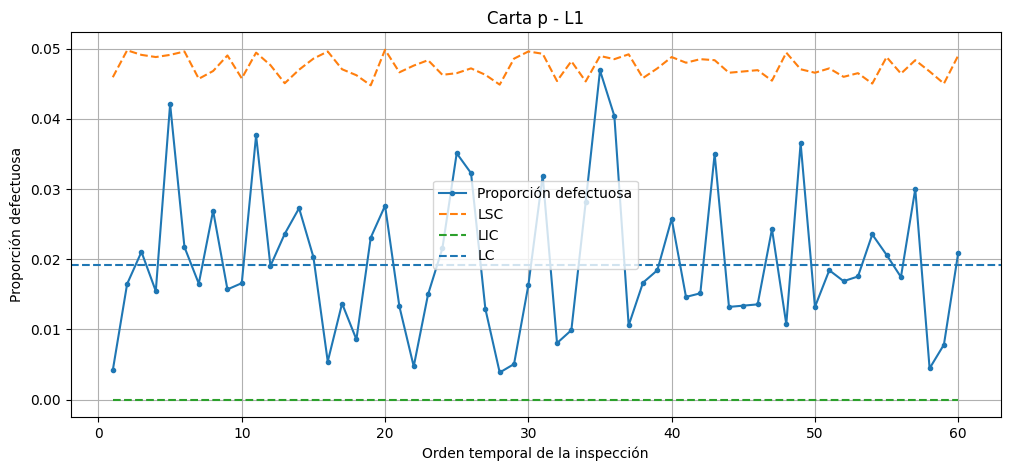


LINEA: L2
p barra: 0.0311
Inspecciones fuera de control:


,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,LSC,causa_principal
84,2026-08-27,6,A (06-14),FUN-B30,198,18,0.090909,0.068181,Nivel de llenado
105,2026-09-07,8,A (06-14),CIT-L30,198,15,0.075758,0.068181,Etiqueta
107,2026-09-07,8,C (22-06),NEC-D30,234,18,0.076923,0.065213,Etiqueta
109,2026-09-08,8,B (14-22),FUN-B15,246,20,0.081301,0.064372,Etiqueta
110,2026-09-08,8,C (22-06),FUN-B15,237,21,0.088608,0.064997,Etiqueta
111,2026-09-09,8,A (06-14),CIT-L30,236,20,0.084746,0.065069,Sello/tapa
113,2026-09-09,8,C (22-06),CIT-L30,231,21,0.090909,0.065434,Etiqueta
114,2026-09-10,8,A (06-14),NEC-D30,225,23,0.102222,0.065888,Nivel de llenado
115,2026-09-10,8,B (14-22),CIT-L30,258,17,0.065891,0.063590,Etiqueta
116,2026-09-10,8,C (22-06),NEC-D30,241,26,0.107884,0.064715,Sello/tapa


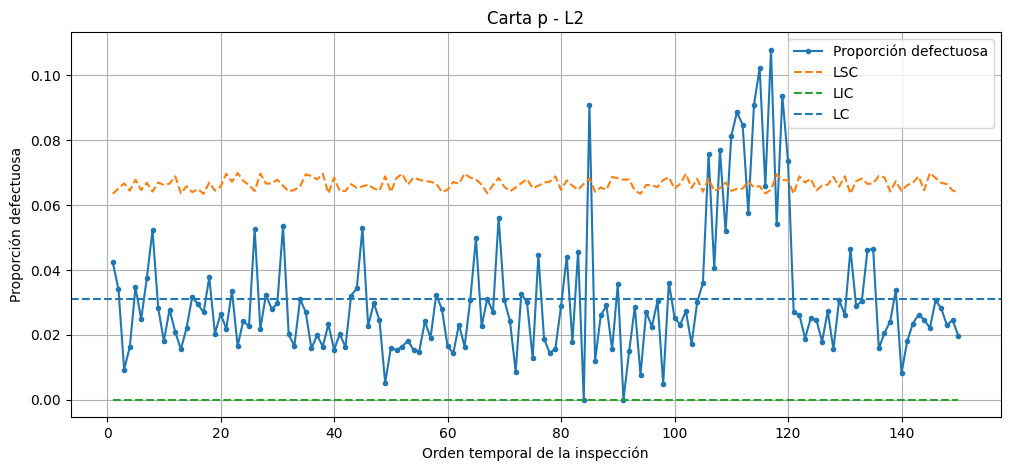


Resumen por línea:


,Linea,Inspecciones,Total_inspeccionadas,Total_defectuosas,p_barra,Porcentaje_defectuoso,Puntos_fuera_control
0,L1,60,12905,248,0.0192,1.92,0
1,L2,150,32974,1027,0.0311,3.11,12



Pareto de causas de defecto:


,causa_principal,n_defectuosas,Porcentaje,Porcentaje_acumulado
0,Etiqueta,440,34.5,34.5
1,Sello/tapa,344,27.0,61.5
2,Nivel de llenado,324,25.4,86.9
3,Envase deformado,92,7.2,94.1
4,Cuerpo extranio,75,5.9,100.0


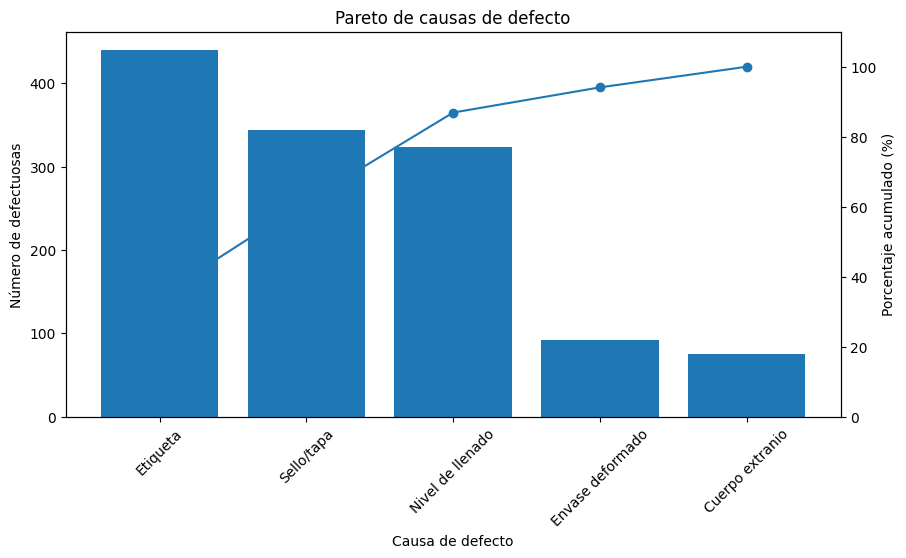

In [53]:
# ============================================================
# CARTA p POR ATRIBUTOS + PARETO DE CAUSAS
# ============================================================

datos_atributos = atributos.copy()

# Proporción defectuosa de cada inspección
datos_atributos["p"] = (
    datos_atributos["n_defectuosas"] /
    datos_atributos["n_inspeccionadas"]
)

resumen_p = []

# ------------------------------------------------------------
# CARTA p POR LÍNEA
# ------------------------------------------------------------

for linea in ["L1", "L2"]:

    datos_linea = datos_atributos[
        datos_atributos["linea"] == linea
    ].copy()

    # Orden temporal
    datos_linea = datos_linea.sort_values(
        ["fecha", "turno"]
    ).reset_index(drop=True)

    datos_linea["orden"] = range(
        1, len(datos_linea) + 1
    )

    # Proporción defectuosa promedio ponderada
    p_barra = (
        datos_linea["n_defectuosas"].sum() /
        datos_linea["n_inspeccionadas"].sum()
    )

    # Límites variables para cada inspección
    error_estandar = np.sqrt(
        p_barra * (1 - p_barra) /
        datos_linea["n_inspeccionadas"]
    )

    datos_linea["LC"] = p_barra

    datos_linea["LSC"] = (
        p_barra + 3 * error_estandar
    )

    datos_linea["LIC"] = (
        p_barra - 3 * error_estandar
    ).clip(lower=0)

    # Identificar puntos fuera de control
    datos_linea["fuera_control"] = (
        (datos_linea["p"] > datos_linea["LSC"]) |
        (datos_linea["p"] < datos_linea["LIC"])
    )

    # Guardar resumen
    resumen_p.append({
        "Linea": linea,
        "Inspecciones": len(datos_linea),
        "Total_inspeccionadas": datos_linea["n_inspeccionadas"].sum(),
        "Total_defectuosas": datos_linea["n_defectuosas"].sum(),
        "p_barra": p_barra,
        "Porcentaje_defectuoso": p_barra * 100,
        "Puntos_fuera_control": datos_linea["fuera_control"].sum()
    })

    # Mostrar puntos fuera de control
    print("\nLINEA:", linea)
    print("p barra:", round(p_barra, 4))

    print("Inspecciones fuera de control:")

    display(
        datos_linea[
            datos_linea["fuera_control"]
        ][
            [
                "fecha",
                "semana_registro",
                "turno",
                "sku",
                "n_inspeccionadas",
                "n_defectuosas",
                "p",
                "LSC",
                "causa_principal"
            ]
        ]
    )

    # Gráfico carta p
    plt.figure(figsize=(12, 5))

    plt.plot(
        datos_linea["orden"],
        datos_linea["p"],
        marker="o",
        markersize=3,
        label="Proporción defectuosa"
    )

    plt.plot(
        datos_linea["orden"],
        datos_linea["LSC"],
        linestyle="--",
        label="LSC"
    )

    plt.plot(
        datos_linea["orden"],
        datos_linea["LIC"],
        linestyle="--",
        label="LIC"
    )

    plt.axhline(
        p_barra,
        linestyle="--",
        label="LC"
    )

    plt.xlabel("Orden temporal de la inspección")
    plt.ylabel("Proporción defectuosa")
    plt.title("Carta p - " + linea)

    plt.legend()
    plt.grid()
    plt.show()


# ------------------------------------------------------------
# RESUMEN DE TASA DEFECTUOSA POR LÍNEA
# ------------------------------------------------------------

resumen_p = pd.DataFrame(resumen_p)

resumen_p["p_barra"] = (
    resumen_p["p_barra"].round(4)
)

resumen_p["Porcentaje_defectuoso"] = (
    resumen_p["Porcentaje_defectuoso"].round(2)
)

print("\nResumen por línea:")
display(resumen_p)


# ------------------------------------------------------------
# PARETO DE CAUSAS DE DEFECTO
# ------------------------------------------------------------

pareto = (
    datos_atributos
    .groupby("causa_principal")["n_defectuosas"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Eliminar "Sin defectos" si su cantidad es 0
pareto = pareto[
    pareto["n_defectuosas"] > 0
].copy()

pareto["Porcentaje"] = (
    pareto["n_defectuosas"] /
    pareto["n_defectuosas"].sum() * 100
)

pareto["Porcentaje_acumulado"] = (
    pareto["Porcentaje"].cumsum()
)

pareto["Porcentaje"] = (
    pareto["Porcentaje"].round(1)
)

pareto["Porcentaje_acumulado"] = (
    pareto["Porcentaje_acumulado"].round(1)
)

print("\nPareto de causas de defecto:")
display(pareto)


# Gráfico de Pareto

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    pareto["causa_principal"],
    pareto["n_defectuosas"]
)

ax1.set_xlabel("Causa de defecto")
ax1.set_ylabel("Número de defectuosas")

plt.xticks(rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    pareto["causa_principal"],
    pareto["Porcentaje_acumulado"],
    marker="o"
)

ax2.set_ylabel("Porcentaje acumulado (%)")
ax2.set_ylim(0, 110)

plt.title("Pareto de causas de defecto")

plt.show()

In [54]:
# ============================================================
# COMPARACIÓN DEL SOBRELLENADO SEGÚN PERÍODO
# ============================================================

comparacion_sobrellenado = []

for (linea, formato), grupo in llenado.groupby(["linea", "formato_L"]):

    nominal = formato * 1000

    # Fase I: semanas 1-2
    fase1 = grupo[
        grupo["semana_registro"].isin([1, 2])
    ]["volumen_mL"]

    # Período completo: semanas 1-10
    completo = grupo["volumen_mL"]

    # Período reciente
    # L1: semanas 6-10, porque detectamos el desplazamiento desde semana 6
    # L2: semanas 3-10, correspondiente a la Fase II monitoreada
    if linea == "L1":
        reciente = grupo[
            grupo["semana_registro"] >= 6
        ]["volumen_mL"]
        periodo_reciente = "Semanas 6-10"
    else:
        reciente = grupo[
            grupo["semana_registro"] >= 3
        ]["volumen_mL"]
        periodo_reciente = "Semanas 3-10"

    comparacion_sobrellenado.append({
        "Linea": linea,
        "Formato_L": formato,
        "Nominal_mL": nominal,

        "Media_F1_mL": fase1.mean(),
        "Sobrellenado_F1_mL": fase1.mean() - nominal,

        "Media_10_sem_mL": completo.mean(),
        "Sobrellenado_10_sem_mL": completo.mean() - nominal,

        "Periodo_reciente": periodo_reciente,
        "Media_reciente_mL": reciente.mean(),
        "Sobrellenado_reciente_mL": reciente.mean() - nominal
    })

comparacion_sobrellenado = pd.DataFrame(comparacion_sobrellenado)

columnas_redondear = [
    "Media_F1_mL",
    "Sobrellenado_F1_mL",
    "Media_10_sem_mL",
    "Sobrellenado_10_sem_mL",
    "Media_reciente_mL",
    "Sobrellenado_reciente_mL"
]

comparacion_sobrellenado[columnas_redondear] = (
    comparacion_sobrellenado[columnas_redondear].round(3)
)

display(comparacion_sobrellenado)

,Linea,Formato_L,Nominal_mL,Media_F1_mL,Sobrellenado_F1_mL,Media_10_sem_mL,Sobrellenado_10_sem_mL,Periodo_reciente,Media_reciente_mL,Sobrellenado_reciente_mL
0,L1,0.5,500.0,502.644,2.644,504.094,4.094,Semanas 6-10,505.720,5.720
1,L2,1.5,1500.0,1504.457,4.457,1504.601,4.601,Semanas 3-10,1504.633,4.633
2,L2,3.0,3000.0,3008.760,8.760,3008.501,8.501,Semanas 3-10,3008.429,8.429


Estimación del sobrellenado medio. Para cuantificar el sobrellenado se comparó el volumen medio observado con el contenido nominal de cada formato. Además, se contrastaron tres períodos: Fase I, las diez semanas completas y el período reciente. Esta comparación se realizó porque las cartas de control mostraron un desplazamiento del nivel medio de llenado en L1 a partir de la semana 6. Por lo tanto, utilizar únicamente el promedio de Fase I podría no representar adecuadamente las condiciones actuales de operación. Para estimar el consumo adicional de producto asociado a la planificación futura se utilizaron los promedios del período reciente.

Resultados de la comparación
Resultados por formato. En L1–0,5 L se observa el cambio más importante: el sobrellenado medio pasó de 2,644 mL por botella durante Fase I a 5,720 mL por botella en las semanas 6 a 10. Este resultado es consistente con el desplazamiento hacia arriba previamente detectado en la carta \(\bar X\), e indica que el régimen reciente presenta un mayor consumo de producto por unidad. En L2 los cambios fueron considerablemente menores: el formato de 1,5 L pasó de 4,457 a 4,633 mL adicionales por botella, mientras que el formato de 3,0 L pasó de 8,760 a 8,429 mL. Por esta razón, el cambio operacional más relevante corresponde al formato de 0,5 L.

Valores que se utilizarán
Sobrellenado representativo. Considerando el comportamiento reciente del proceso, se adoptaron como parámetros de sobrellenado medio 5,720 mL por botella para el formato de 0,5 L, 4,633 mL para 1,5 L y 8,429 mL para 3,0 L. Estos valores representan el contenido adicional promedio entregado respecto del volumen nominal de cada formato y serán utilizados para cuantificar el consumo adicional de producto y su impacto económico.

Conversión a litros adicionales por caja. Para traducir el sobrellenado a una medida operacional, el exceso medio por botella se multiplicó por el número de botellas contenidas en cada caja. Así, el formato de 0,5 L, con 12 botellas por caja, consume aproximadamente 0,06864 L adicionales por caja; el formato de 1,5 L, con 6 botellas, consume 0,02780 L adicionales; y el formato de 3,0 L, con 4 botellas por caja, consume 0,03372 L adicionales. Aunque el formato de 3,0 L presenta el mayor sobrellenado en mL por botella, el formato de 0,5 L genera el mayor consumo adicional por caja debido a la mayor cantidad de botellas contenidas en ella.

Interpretación operacional
Interpretación. El sobrellenado representa producto que cumple o incluso excede el contenido nominal, pero que no genera ingresos adicionales para la empresa. Por ello, constituye un consumo adicional de materia prima y capacidad de mezcla. El caso más relevante es L1–0,5 L, donde el desplazamiento reciente del proceso elevó significativamente el exceso medio por botella. Corregir el centrado del proceso permitiría reducir este consumo adicional sin necesariamente modificar su variabilidad. El siguiente paso consiste en combinar los litros adicionales por caja con el volumen anual de producción para estimar los litros de producto entregados en exceso y su costo variable anual.

In [55]:
print(maestro.columns.tolist())
display(maestro.head())

['sku', 'familia', 'nombre_familia', 'sabor', 'formato_L', 'botellas_por_caja', 'litros_por_caja', 'linea_envasado', 'tasa_envasado_cajas_h', 'costo_variable_caja_clp', 'precio_lista_caja_clp', 'costo_inventario_caja_semana_clp', 'penalidad_atraso_caja_semana_clp']


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400


Revisar los valores monetarios de los productos

In [56]:
# ============================================================
# CUANTIFICACIÓN ECONÓMICA DEL SOBRELLENADO
# ============================================================

# Sobrellenado representativo del período reciente
sobrellenado_formato = pd.DataFrame({
    "formato_L": [0.5, 1.5, 3.0],
    "sobrellenado_mL_botella": [5.720, 4.633, 8.429]
})

# ------------------------------------------------------------
# 1. Ventas de las últimas 52 semanas
# ------------------------------------------------------------

semana_max = demanda["semana"].max()

ventas_52 = demanda[
    demanda["semana"] > semana_max - 52
].copy()

ventas_anuales = (
    ventas_52
    .groupby("sku", as_index=False)["ventas_cajas"]
    .sum()
    .rename(columns={"ventas_cajas": "cajas_anuales"})
)

# ------------------------------------------------------------
# 2. Agregar información del maestro
# ------------------------------------------------------------

sobrellenado_anual = ventas_anuales.merge(
    maestro[
        [
            "sku",
            "familia",
            "formato_L",
            "botellas_por_caja",
            "litros_por_caja",
            "linea_envasado",
            "costo_variable_caja_clp"
        ]
    ],
    on="sku",
    how="left"
)

sobrellenado_anual = sobrellenado_anual.merge(
    sobrellenado_formato,
    on="formato_L",
    how="left"
)

# ------------------------------------------------------------
# 3. Litros adicionales por caja
# ------------------------------------------------------------

sobrellenado_anual["sobrellenado_L_caja"] = (
    sobrellenado_anual["sobrellenado_mL_botella"]
    * sobrellenado_anual["botellas_por_caja"]
    / 1000
)

# ------------------------------------------------------------
# 4. Litros adicionales al año
# ------------------------------------------------------------

sobrellenado_anual["litros_extra_anuales"] = (
    sobrellenado_anual["cajas_anuales"]
    * sobrellenado_anual["sobrellenado_L_caja"]
)

# ------------------------------------------------------------
# 5. Costo variable aproximado por litro
# ------------------------------------------------------------

sobrellenado_anual["costo_variable_L_clp"] = (
    sobrellenado_anual["costo_variable_caja_clp"]
    / sobrellenado_anual["litros_por_caja"]
)

# ------------------------------------------------------------
# 6. Costo anual del sobrellenado
# ------------------------------------------------------------

sobrellenado_anual["costo_sobrellenado_anual_clp"] = (
    sobrellenado_anual["litros_extra_anuales"]
    * sobrellenado_anual["costo_variable_L_clp"]
)

# Redondear
columnas_redondear = [
    "sobrellenado_L_caja",
    "litros_extra_anuales",
    "costo_variable_L_clp",
    "costo_sobrellenado_anual_clp"
]

sobrellenado_anual[columnas_redondear] = (
    sobrellenado_anual[columnas_redondear].round(2)
)

print("DETALLE POR SKU")
display(
    sobrellenado_anual[
        [
            "sku",
            "familia",
            "formato_L",
            "cajas_anuales",
            "sobrellenado_mL_botella",
            "sobrellenado_L_caja",
            "litros_extra_anuales",
            "costo_variable_L_clp",
            "costo_sobrellenado_anual_clp"
        ]
    ]
)

# ------------------------------------------------------------
# 7. Resumen por formato
# ------------------------------------------------------------

resumen_sobrellenado = (
    sobrellenado_anual
    .groupby("formato_L", as_index=False)
    .agg(
        cajas_anuales=("cajas_anuales", "sum"),
        litros_extra_anuales=("litros_extra_anuales", "sum"),
        costo_sobrellenado_anual_clp=(
            "costo_sobrellenado_anual_clp", "sum"
        )
    )
)

resumen_sobrellenado[
    ["litros_extra_anuales", "costo_sobrellenado_anual_clp"]
] = resumen_sobrellenado[
    ["litros_extra_anuales", "costo_sobrellenado_anual_clp"]
].round(0)

print("\nRESUMEN POR FORMATO")
display(resumen_sobrellenado)

# ------------------------------------------------------------
# 8. Total planta
# ------------------------------------------------------------

total_litros = sobrellenado_anual["litros_extra_anuales"].sum()
total_costo = sobrellenado_anual["costo_sobrellenado_anual_clp"].sum()

print("\nTOTAL PLANTA")
print("Litros adicionales al año:", round(total_litros, 0))
print("Costo variable anual estimado: $", round(total_costo, 0))

DETALLE POR SKU


,sku,familia,formato_L,cajas_anuales,sobrellenado_mL_botella,sobrellenado_L_caja,litros_extra_anuales,costo_variable_L_clp,costo_sobrellenado_anual_clp
0,CIT-L05,CIT,0.5,133114.0,5.720,0.07,9136.94,470.0,4294364.13
1,CIT-L15,CIT,1.5,114955.0,4.633,0.03,3195.52,470.0,1501893.97
2,CIT-L30,CIT,3.0,22513.0,8.429,0.03,759.05,470.0,356752.70
3,FUN-B05,FUN,0.5,128996.0,5.720,0.07,8854.29,810.0,7171971.21
4,FUN-B15,FUN,1.5,90729.0,4.633,0.03,2522.08,810.0,2042888.64
5,FUN-B30,FUN,3.0,7580.0,8.429,0.03,255.57,810.0,207009.50
6,NEC-D05,NEC,0.5,79233.0,5.720,0.07,5438.55,640.0,3480674.00
7,NEC-D15,NEC,1.5,139996.0,4.633,0.03,3891.61,640.0,2490629.64
8,NEC-D30,NEC,3.0,32359.0,8.429,0.03,1091.02,640.0,698250.27



RESUMEN POR FORMATO


,formato_L,cajas_anuales,litros_extra_anuales,costo_sobrellenado_anual_clp
0,0.5,341343.0,23430.0,14947009.0
1,1.5,345680.0,9609.0,6035412.0
2,3.0,62452.0,2106.0,1262012.0



TOTAL PLANTA
Litros adicionales al año: 35145.0
Costo variable anual estimado: $ 22244434.0


Cuantificación económica del sobrellenado. Utilizando como referencia el comportamiento reciente del proceso y las ventas de las últimas 52 semanas como aproximación del volumen anual, se estimó que el sobrellenado genera aproximadamente 35.145 litros adicionales de producto al año. Valorizados mediante el costo variable equivalente por litro de cada SKU, estos representan un costo aproximado de $22,24 millones anuales. El formato de 0,5 L concentra el mayor impacto, con 23.430 litros adicionales y un costo cercano a 14,95 millones anuales, equivalentes a aproximadamente dos tercios del volumen total sobrellenado. Este resultado es consistente con el desplazamiento de la media detectado previamente en L1, especialmente desde la semana 6.


Supuesto de cálculo. Debido a que la base disponible registra ventas y no producción efectiva, se utilizaron las ventas de las últimas 52 semanas como aproximación del volumen anual producido. Asimismo, dado que no se dispone de un costo específico del jarabe por litro, se estimó un costo variable equivalente por litro a partir del costo variable y los litros nominales por caja. Por ello, el resultado debe interpretarse como una estimación económica del impacto del sobrellenado. Una vez reconstruida la demanda en la Parte B, el cálculo puede actualizarse si se considera necesario.


Las líneas presentan patologías distintas. L2 concentra el mayor problema de calidad por atributos, con una fracción defectuosa de 3,11 % y episodios de deterioro estadístico. En cambio, L1 concentra el mayor impacto económico asociado al sobrellenado, con aproximadamente 23.430 litros adicionales y $14,95 millones de costo variable al año.




El análisis demuestra que estabilidad estadística y capacidad de proceso son conceptos distintos: un proceso puede presentar un comportamiento predecible y, aun así, no ser capaz de cumplir consistentemente las especificaciones. En Bebidas del Maipo, ninguno de los tres procesos alcanza un \(Cpk\) global de 1,33, aunque las causas del problema difieren. L1–0,5 L presenta principalmente un problema de centrado, evidenciado por la diferencia entre \(Cp=1,306\) y \(Cpk=0,874\), además del desplazamiento ascendente observado desde la semana 6. En L2–1,5 L, \(Cp=0,998\) muestra que también existe un problema importante de variabilidad, mientras que L2–3,0 L combina un centrado deficiente con una capacidad potencial ajustada. Por lo tanto, no corresponde aplicar la misma acción a todos los procesos: los problemas de media requieren recalibración o ajuste del setpoint, mientras que los problemas de dispersión requieren intervenir las fuentes de variabilidad del proceso.
En el análisis por atributos, L1 presentó una tasa defectuosa de 1,92 %, mientras que L2 alcanzó 3,11 % y registró 12 inspecciones sobre el límite superior de control, principalmente concentradas en la semana 8. El Pareto mostró que Etiqueta, Sello/tapa y Nivel de llenado concentran el 86,9 % de las unidades defectuosas. Por otro lado, el impacto económico del sobrellenado se concentra en L1–0,5 L: se estimaron aproximadamente 35.145 litros adicionales al año para toda la planta, equivalentes a 22,24 millones anuales de costo variable, de los cuales 23.430 litros y aproximadamente $14,95 millones corresponden al formato de 0,5 L. En consecuencia, L2 presenta el mayor problema asociado a defectos, mientras que L1 presenta el mayor impacto económico por sobrellenado.
